<a href="https://colab.research.google.com/github/arielsharonferdinandus/Transboundary-Haze-Forecasting/blob/baseline-and-candidate-models/Transboundary_Haze_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transboundary Haze Forecasting: Predicting PM2.5 Spikes in Singapore
**Theme:** Energy & Environment (Air Quality) | **Type:** Time-Series Forecasting

**This notebook (Parts 1-2 of the project)**
- **Part 1:** problem formulation, data audit, cleaning, merging, EDA (Phases 1-2)
- **Part 2:** feature engineering, forecast targets, leakage tests, chronological split (Phase 3)
- **Part 3:** naive baselines, SARIMAX, Holt-Winters, LightGBM, Ridge, evaluated on validation and test (Phase 4), plus a running **Limitations** section
- *Parts 4+ (tuning, interpretation, recommendations) will be appended next.*

**How to run on Colab:** Runtime > Run all. When the data cell asks for files, upload the two station CSVs
(Marina Bay `openaq_location_6546759_...` and Alexandra Canal `openaq_location_6536821_...`). Files of other stations are ignored if you include them.
Everything after that runs without any further upload.

## Part 1: Problem Formulation, Data Audit & Preprocessing (Phases 1-2)

**Stakeholder:** National Environment Agency (NEA) Singapore / Director of Public Health.

**Predictive question:** Can historical PM2.5 and meteorological sensor data across Singapore sites forecast PM2.5 spikes 24-48 hours ahead during Indonesian land and forest fire (karhutla) haze events?

**Target:** `pm25` (ug/m3), hourly, per station and city-wide mean.

**Unit of analysis:** hourly timestamp x sensor location (Marina Bay, Alexandra Canal).

> Data note: two of the four exported stations are **excluded** because they cannot share a time window with the others: *Waterscape at Cavenagh* (6551473) has only 91 hours (10-14 Oct 2026), and *Marine Terrace* (6301631) covers 9 Apr - 7 Jun 2026 only, with no overlap with Alexandra Canal / Marina Bay (12 Sep - 14 Oct). The notebook ignores their files if you upload them.

> Scope note: the model *predicts haze arrival from observed air-quality signals*. It does not simulate fire ignition and makes no causal claims about fires.

## Part 1 · 0. Setup

In [ ]:
!pip -q install pandas numpy matplotlib seaborn
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)

## Part 1 · 1. Load the data
Put the station CSVs (Marina Bay, Alexandra Canal) in a `data/` folder. On Colab, run the cell below: if the files are not found it opens an upload dialog and saves them into `data/`.

In [ ]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

STATIONS = {
    "6546759": "Marina Bay",
    # "6301631": "Marine Terrace",   # excluded: Apr-Jun 2026 only, no overlap with the other stations
    # "6551473": "Waterscape at Cavenagh",   # excluded: only 91 hours
    "6536821": "Alexandra Canal",
}

def find_files():
    fs = sorted(glob.glob(os.path.join(DATA_DIR, "openaq_location_*_measurments.csv")) +
                glob.glob(os.path.join(DATA_DIR, "openaq_location_*_measurements.csv")))
    return [f for f in fs if any(k in os.path.basename(f) for k in STATIONS)]   # files of other stations (e.g. 6551473) are ignored

if len(find_files()) < len(STATIONS):
    try:
        from google.colab import files
        print("Upload the openaq_location_*.csv files for:", list(STATIONS.values()))
        up = files.upload()
        for name, content in up.items():
            with open(os.path.join(DATA_DIR, name), "wb") as f:
                f.write(content)
    except ImportError:
        print("Not on Colab: copy the CSVs into ./data manually.")

files_found = find_files()
print(len(files_found), "files found:")
for f in files_found: print("  ", f)
assert len(files_found) == len(STATIONS), f"Expected {len(STATIONS)} station files, found {len(files_found)}"

2 files found:
   data/openaq_location_6536821_measurments.csv
   data/openaq_location_6546759_measurments.csv


In [ ]:
raw = {}
for f in files_found:
    loc_id = [k for k in STATIONS if k in f][0]
    df = pd.read_csv(f)
    df["station"] = STATIONS[loc_id]
    raw[STATIONS[loc_id]] = df
    print(f"{STATIONS[loc_id]:25s} shape={df.shape}")

# Inspect structure of the first file
first = next(iter(raw.values()))
print("\nColumns:", list(first.columns))
first.head()

Alexandra Canal           shape=(3770, 16)
Marina Bay                shape=(3075, 16)

Columns: ['location_id', 'location_name', 'parameter', 'value', 'unit', 'datetimeUtc', 'datetimeLocal', 'timezone', 'latitude', 'longitude', 'country_iso', 'isMobile', 'isMonitor', 'owner_name', 'provider', 'station']


,location_id,location_name,parameter,value,unit,datetimeUtc,datetimeLocal,timezone,latitude,longitude,country_iso,isMobile,isMonitor,owner_name,provider,station
0,6536821,Alexandra Canal,pm1,0.0,µg/m³,2026-09-12T15:00:00Z,2026-09-12T23:00:00+08:00,Asia/Singapore,1.29213,103.82421,NaN,NaN,NaN,One Jervois,AirGradient,Alexandra Canal
1,6536821,Alexandra Canal,pm1,28.4,µg/m³,2026-09-12T16:00:00Z,2026-09-13T00:00:00+08:00,Asia/Singapore,1.29213,103.82421,NaN,NaN,NaN,One Jervois,AirGradient,Alexandra Canal
2,6536821,Alexandra Canal,pm1,29.6,µg/m³,2026-09-12T17:00:00Z,2026-09-13T01:00:00+08:00,Asia/Singapore,1.29213,103.82421,NaN,NaN,NaN,One Jervois,AirGradient,Alexandra Canal
3,6536821,Alexandra Canal,pm1,30.3,µg/m³,2026-09-12T18:00:00Z,2026-09-13T02:00:00+08:00,Asia/Singapore,1.29213,103.82421,NaN,NaN,NaN,One Jervois,AirGradient,Alexandra Canal
4,6536821,Alexandra Canal,pm1,30.8,µg/m³,2026-09-12T19:00:00Z,2026-09-13T03:00:00+08:00,Asia/Singapore,1.29213,103.82421,NaN,NaN,NaN,One Jervois,AirGradient,Alexandra Canal


In [ ]:
# Combine into one long dataframe and inspect parameters
long_raw = pd.concat(raw.values(), ignore_index=True)
print(long_raw["parameter"].value_counts(), "\n")
print("Units per parameter:")
print(long_raw.groupby("parameter")["unit"].unique(), "\n")
print("Rows per station x parameter:")
long_raw.groupby(["station", "parameter"]).size().unstack(fill_value=0)

parameter
pm1                 1369
pm25                1369
relativehumidity    1369
temperature         1369
um003               1369
Name: count, dtype: int64 

Units per parameter:
parameter
pm1                         [µg/m³]
pm25                        [µg/m³]
relativehumidity                [%]
temperature                     [c]
um003               [particles/cm³]
Name: unit, dtype: object 

Rows per station x parameter:


parameter,pm1,pm25,relativehumidity,temperature,um003
station,,,,,
Alexandra Canal,754,754,754,754,754
Marina Bay,615,615,615,615,615


## Part 1 · 2. Data audit (raw)
Checks: missing values, duplicates, invalid sensor values (negative PM2.5, humidity outside 0-100%, exact-zero PM readings), time coverage and sampling interval.

In [ ]:
# Parse timestamps (datetimeLocal; drop the +08:00 offset so everything is Singapore wall-clock time)
ts = pd.to_datetime(long_raw["datetimeLocal"], errors="coerce")
if getattr(ts.dt, "tz", None) is not None:
    ts = ts.dt.tz_localize(None)
long_raw["time"] = ts
long_raw["value"] = pd.to_numeric(long_raw["value"], errors="coerce")

audit = pd.DataFrame({
    "null_time": [long_raw["time"].isna().sum()],
    "null_value": [long_raw["value"].isna().sum()],
    "duplicate_rows(station,time,param)": [long_raw.duplicated(["station", "time", "parameter"]).sum()],
})
display(audit)

print("Time coverage per station (all parameters):")
display(long_raw.groupby("station")["time"].agg(["min", "max", "count"]))

,null_time,null_value,"duplicate_rows(station,time,param)"
0,0,0,0


Time coverage per station (all parameters):


,min,max,count
station,,,
Alexandra Canal,2026-09-12 23:00:00,2026-10-14 08:00:00,3770
Marina Bay,2026-09-18 18:00:00,2026-10-14 08:00:00,3075


In [ ]:
# Value ranges and invalid values per parameter
display(long_raw.groupby("parameter")["value"].describe().round(2))

P = long_raw.parameter
invalid = {
    "negative pm25":                           ((P == "pm25") & (long_raw.value < 0)).sum(),
    "negative pm1":                            ((P == "pm1") & (long_raw.value < 0)).sum(),
    "exact zero pm25 (sensor dropout/warm-up)": ((P == "pm25") & (long_raw.value == 0)).sum(),
    "exact zero pm1":                          ((P == "pm1") & (long_raw.value == 0)).sum(),
    "humidity <0 or >100":                     ((P == "relativehumidity") & ((long_raw.value < 0) | (long_raw.value > 100))).sum(),
    "temperature <15 or >45 C (implausible)":  ((P == "temperature") & ((long_raw.value < 15) | (long_raw.value > 45))).sum(),
    "negative um003":                          ((P == "um003") & (long_raw.value < 0)).sum(),
    "pm25 < pm1 (physically inconsistent)":    0,
}
# pm25 < pm1 check on matching timestamps
pv = long_raw[long_raw.parameter.isin(["pm1", "pm25"])].pivot_table(index=["station", "time"], columns="parameter", values="value")
invalid["pm25 < pm1 (physically inconsistent)"] = int((pv["pm25"] < pv["pm1"]).sum())
print("Invalid / suspicious counts:")
for k, v in invalid.items(): print(f"  {k:45s} {v}")

,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm1,1369.0,43.47,19.57,0.0,28.0,38.0,58.9,99.4
pm25,1369.0,79.78,41.56,0.0,45.2,68.2,110.6,204.1
relativehumidity,1369.0,58.39,5.83,41.0,55.0,60.0,62.0,74.0
temperature,1369.0,29.62,1.71,24.9,28.6,29.2,30.5,35.0
um003,1369.0,3184.75,1605.40,113.0,1802.0,2902.0,4455.0,7455.0


Invalid / suspicious counts:
  negative pm25                                 0
  negative pm1                                  0
  exact zero pm25 (sensor dropout/warm-up)      1
  exact zero pm1                                1
  humidity <0 or >100                           0
  temperature <15 or >45 C (implausible)        0
  negative um003                                0
  pm25 < pm1 (physically inconsistent)          0


In [ ]:
# Sampling interval (irregular timestamps?) for pm25
pm = long_raw[long_raw.parameter == "pm25"].sort_values(["station", "time"])
pm["gap"] = pm.groupby("station")["time"].diff()
print("Sampling intervals between consecutive pm25 readings (all stations):")
display(pm["gap"].value_counts().sort_index().to_frame("count"))
print("Gaps longer than 3 hours:")
display(pm.loc[pm["gap"] > pd.Timedelta("3h"), ["station", "time", "gap"]])

Sampling intervals between consecutive pm25 readings (all stations):


,count
gap,
0 days 01:00:00,1367


Gaps longer than 3 hours:


,station,time,gap


## Part 1 · 3. Cleaning & hourly resampling
Steps:
1. Drop rows with unparseable time or value.
2. Set invalid values to NaN: negative PM, **exact-zero PM1/PM2.5** (sensor start-up / dropout readings, not real air), humidity outside 0-100, implausible temperature.
3. Average duplicates and resample every series to a regular **hourly** grid.

In [ ]:
clean = long_raw.dropna(subset=["time", "value"]).copy()

bad = (
    (clean.parameter.isin(["pm1", "pm25", "um003"]) & (clean.value < 0)) |
    (clean.parameter.isin(["pm1", "pm25"]) & (clean.value == 0)) |
    ((clean.parameter == "relativehumidity") & ~clean.value.between(0, 100)) |
    ((clean.parameter == "temperature") & ~clean.value.between(15, 45))
)
print("Rows set to NaN as invalid:", int(bad.sum()))
clean.loc[bad, "value"] = np.nan

clean["hour"] = clean["time"].dt.floor("h")
hourly = (clean.groupby(["station", "parameter", "hour"])["value"].mean()
               .reset_index())
print("Hourly records:", len(hourly))
hourly.head()

Rows set to NaN as invalid: 2
Hourly records: 6845


,station,parameter,hour,value
0,Alexandra Canal,pm1,2026-09-12 23:00:00,NaN
1,Alexandra Canal,pm1,2026-09-13 00:00:00,28.4
2,Alexandra Canal,pm1,2026-09-13 01:00:00,29.6
3,Alexandra Canal,pm1,2026-09-13 02:00:00,30.3
4,Alexandra Canal,pm1,2026-09-13 03:00:00,30.8


## Part 1 · 4. Wide-format merge across stations
Columns are named `{parameter}__{station}`, indexed by a complete hourly `DatetimeIndex`.

In [ ]:
PARAMS = ["pm1", "pm25", "relativehumidity", "temperature", "um003"]
wide = hourly.pivot_table(index="hour", columns=["parameter", "station"], values="value")
wide.columns = [f"{p}__{s.replace(' ', '_')}" for p, s in wide.columns]

full_idx = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(full_idx)
wide.index.name = "datetime"
print("Merged grid:", wide.shape, "|", wide.index.min(), "->", wide.index.max())
wide.iloc[:3, :6]

Merged grid: (754, 10) | 2026-09-12 23:00:00 -> 2026-10-14 08:00:00


,pm1__Alexandra_Canal,pm1__Marina_Bay,pm25__Alexandra_Canal,pm25__Marina_Bay,relativehumidity__Alexandra_Canal,relativehumidity__Marina_Bay
datetime,,,,,,
2026-09-12 23:00:00,NaN,NaN,NaN,NaN,45.0,NaN
2026-09-13 00:00:00,28.4,NaN,46.3,NaN,65.0,NaN
2026-09-13 01:00:00,29.6,NaN,48.3,NaN,62.0,NaN


### 4a. Coverage & overlap between stations
**This step matters:** a city-wide mean and cross-station features only make sense where stations are observed at the same time.

,first,last,span_hours,observed_hours,missing_inside_span
station,,,,,
Alexandra_Canal,2026-09-13 00:00:00,2026-10-14 08:00:00,753,753,0
Marina_Bay,2026-09-18 18:00:00,2026-10-14 08:00:00,615,615,0


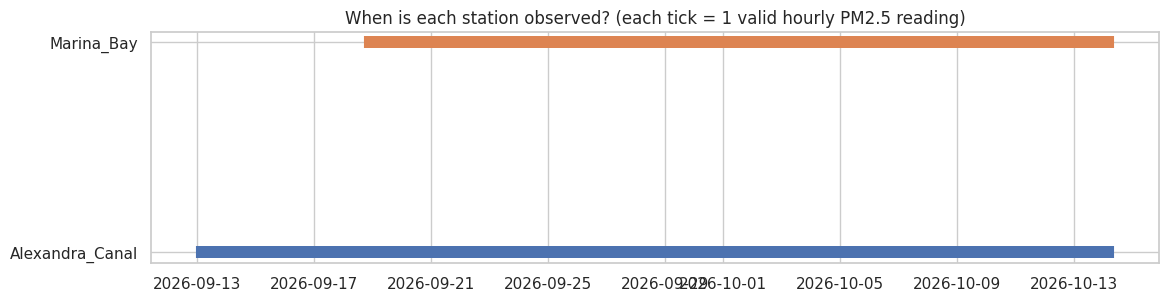

In [ ]:
pm_all = [c for c in wide.columns if c.startswith("pm25__")]
rows = []
for c in pm_all:
    s = wide[c]; first, last = s.first_valid_index(), s.last_valid_index()
    inside = s.loc[first:last]
    rows.append({"station": c.replace("pm25__", ""), "first": first, "last": last,
                 "span_hours": len(inside), "observed_hours": int(inside.notna().sum()),
                 "missing_inside_span": int(inside.isna().sum())})
coverage = pd.DataFrame(rows).set_index("station")
display(coverage)

fig, ax = plt.subplots(figsize=(13, 3))
for i, c in enumerate(pm_all):
    idx = wide[c].dropna().index
    ax.scatter(idx, [i] * len(idx), marker="|", s=80)
ax.set_yticks(range(len(pm_all))); ax.set_yticklabels([c.replace("pm25__", "") for c in pm_all])
ax.set_title("When is each station observed? (each tick = 1 valid hourly PM2.5 reading)")
plt.show()

In [ ]:
# ---- CONFIG: stations used to build the city-wide mean and the modelling window ----
# Default = stations whose observation periods overlap for a long continuous stretch.
# To add a station later: uncomment it in STATIONS (section 1), add its name here and re-run.
CORE_STATIONS = ["Alexandra_Canal", "Marina_Bay"]

core_pm = [f"pm25__{s}" for s in CORE_STATIONS]
MODEL_START = max(wide[c].first_valid_index() for c in core_pm)
MODEL_END   = min(wide[c].last_valid_index()  for c in core_pm)
n_hours = int((MODEL_END - MODEL_START) / pd.Timedelta("1h")) + 1
print(f"Core stations : {CORE_STATIONS}")
print(f"Modelling window: {MODEL_START}  ->  {MODEL_END}  ({n_hours} hours = {n_hours/24:.1f} days)")

print("\nValid PM2.5 hours inside the modelling window, per station:")
inwin = wide.loc[MODEL_START:MODEL_END, pm_all].notna().sum()
display(inwin.rename(lambda c: c.replace("pm25__", "")).to_frame("hours_in_window"))

Core stations : ['Alexandra_Canal', 'Marina_Bay']
Modelling window: 2026-09-18 18:00:00  ->  2026-10-14 08:00:00  (615 hours = 25.6 days)

Valid PM2.5 hours inside the modelling window, per station:


,hours_in_window
Alexandra_Canal,615
Marina_Bay,615


**What this means for the project** (based on the provided exports; the cell above prints the exact numbers):
- Only stations observed in the same period can share a city-wide mean. The two stations kept here overlap for the whole window; the other two exports (Marine Terrace, Waterscape) were dropped for the reason given in the data note at the top.
- The modelling window is short (a few weeks of hourly data). Forecast evaluation will rest on only a few days of test data, and month / season features carry no information within one season.
- Low-cost optical (AirGradient) sensors can read higher than regulatory monitors in haze. Treat absolute levels with caution; relative spikes and timing are the strength of this data.
- NEA's *1-hour* PM2.5 bands (Normal <=55, Elevated 56-150, High 151-250, Very High >250 ug/m3) are used below as a reference scale. They are not themselves health advisories (those use the 24-hour PSI).

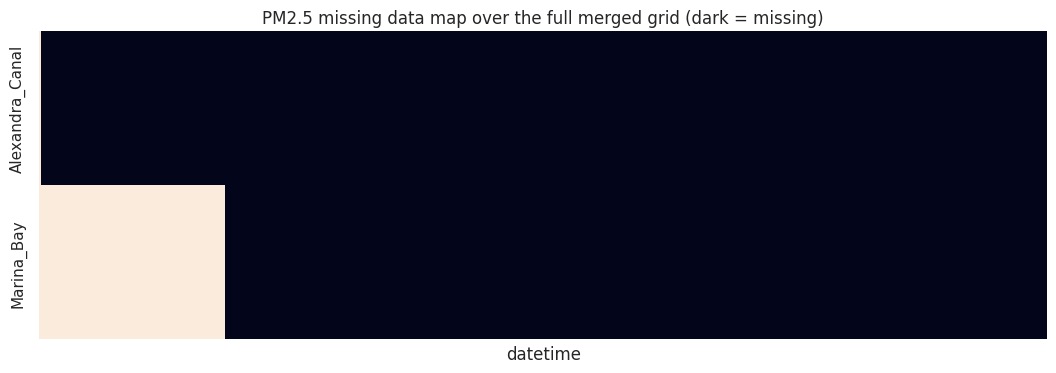

In [ ]:
# Missingness on the full grid (shows the non-overlap clearly)
plt.figure(figsize=(13, 4))
sns.heatmap(wide[pm_all].isna().T, cbar=False, xticklabels=False,
            yticklabels=[c.replace("pm25__", "") for c in pm_all])
plt.title("PM2.5 missing data map over the full merged grid (dark = missing)")
plt.show()

## Part 1 · 5. Missing-value handling (no leakage)
- **Forward-fill, at most 6 hours** per gap. It only uses past values, so it cannot leak future information into training or test periods.
- Values are never filled **before a series starts or after it ends** (so a station is not extended beyond its real observation period).
- Longer gaps stay NaN and are dropped later (after lag creation) rather than inventing data.
- No mean / median imputation. Any scaling later is fit on the **train split only**.

In [ ]:
filled = wide.ffill(limit=6)
for c in wide.columns:                       # do not extend a series past its last real reading
    last = wide[c].last_valid_index()
    if last is not None:
        filled.loc[filled.index > last, c] = np.nan

print(f"NaN cells (full grid): {int(wide.isna().sum().sum())} -> {int(filled.isna().sum().sum())}")
print("Hours filled by forward-fill, per PM2.5 column:")
display((filled[pm_all].notna().sum() - wide[pm_all].notna().sum()).to_frame("hours_filled"))

NaN cells (full grid): 697 -> 697
Hours filled by forward-fill, per PM2.5 column:


,hours_filled
pm25__Alexandra_Canal,0
pm25__Marina_Bay,0


## Part 1 · 6. Build the modelling dataframe
Slice to the overlap window, keep only columns that actually have data in it, and compute the **city-wide mean over the core stations** (spatial aggregation).

In [ ]:
model = filled.loc[MODEL_START:MODEL_END].copy()
keep = [c for c in model.columns if model[c].notna().any()]
dropped = [c for c in model.columns if c not in keep]
model = model[keep]
print("Columns without any data in the window (excluded):", sorted({c.split('__')[1] for c in dropped}))

for p in PARAMS:
    cols = [f"{p}__{s}" for s in CORE_STATIONS if f"{p}__{s}" in model.columns]
    model[f"{p}_citymean"] = model[cols].mean(axis=1, skipna=True)
model["n_core_stations_pm25"] = model[core_pm].notna().sum(axis=1)

print("Model frame:", model.shape)
print("NaN in pm25_citymean:", int(model["pm25_citymean"].isna().sum()))
print("Hours with fewer than all core stations reporting:", int((model["n_core_stations_pm25"] < len(CORE_STATIONS)).sum()))
model[[c for c in model.columns if c.startswith("pm25")]].describe().round(1)

Columns without any data in the window (excluded): []
Model frame: (615, 16)
NaN in pm25_citymean: 0
Hours with fewer than all core stations reporting: 0


,pm25__Alexandra_Canal,pm25__Marina_Bay,pm25_citymean
count,615.0,615.0,615.0
mean,87.0,76.2,81.6
std,45.2,38.0,41.3
min,4.4,6.4,5.4
25%,46.8,43.8,45.2
50%,76.3,65.4,70.9
75%,123.8,105.2,113.7
max,204.1,194.2,199.1


## Part 1 · 7. Exploratory data analysis (modelling window)

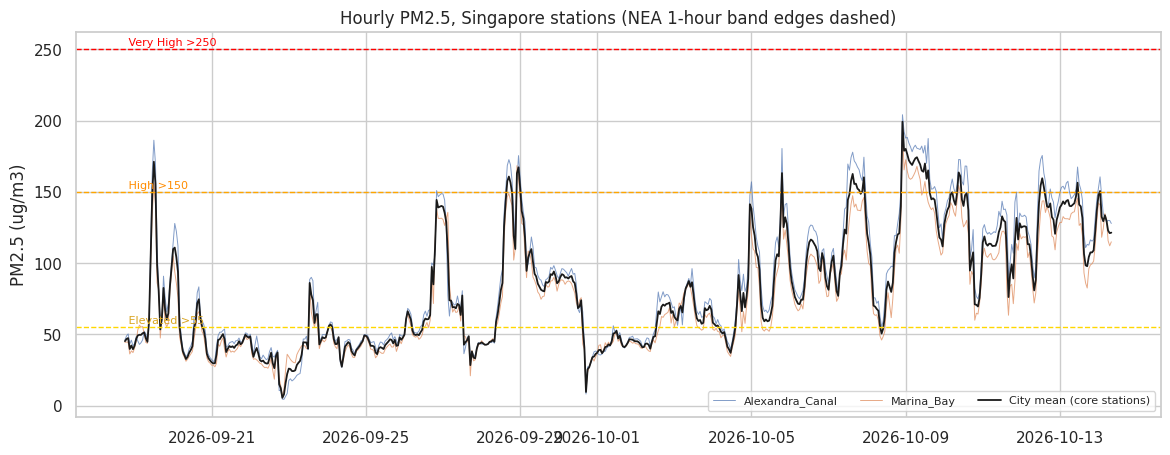

In [ ]:
BANDS = [55, 150, 250]
pm_cols_model = [c for c in model.columns if c.startswith("pm25__")]

fig, ax = plt.subplots(figsize=(14, 5))
for c in pm_cols_model:
    ax.plot(model.index, model[c], lw=0.7, alpha=0.7, label=c.replace("pm25__", ""))
ax.plot(model.index, model["pm25_citymean"], color="k", lw=1.3, label="City mean (core stations)")
for b, col in zip(BANDS, ["gold", "orange", "red"]):
    ax.axhline(b, color=col, ls="--", lw=1)
ax.text(model.index[0], 56, " Elevated >55", color="goldenrod", fontsize=8, va="bottom")
ax.text(model.index[0], 151, " High >150", color="darkorange", fontsize=8, va="bottom")
ax.text(model.index[0], 251, " Very High >250", color="red", fontsize=8, va="bottom")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("Hourly PM2.5, Singapore stations (NEA 1-hour band edges dashed)")
ax.legend(ncol=3, fontsize=8); plt.show()

In [ ]:
# Time spent in each NEA 1-hour PM2.5 band
labels = ["Normal (<=55)", "Elevated (56-150)", "High (151-250)", "Very High (>250)"]
def band_share(s):
    return pd.cut(s.dropna(), [-np.inf, 55, 150, 250, np.inf], labels=labels).value_counts(normalize=True).reindex(labels).mul(100).round(1)
tbl = pd.DataFrame({"City mean": band_share(model["pm25_citymean"]),
                    **{c.replace("pm25__", ""): band_share(model[c]) for c in pm_cols_model}})
print("% of hours in each band:"); display(tbl)

% of hours in each band:


,City mean,Alexandra_Canal,Marina_Bay
Normal (<=55),36.9,35.0,40.8
Elevated (56-150),56.4,52.5,56.3
High (151-250),6.7,12.5,2.9
Very High (>250),0.0,0.0,0.0


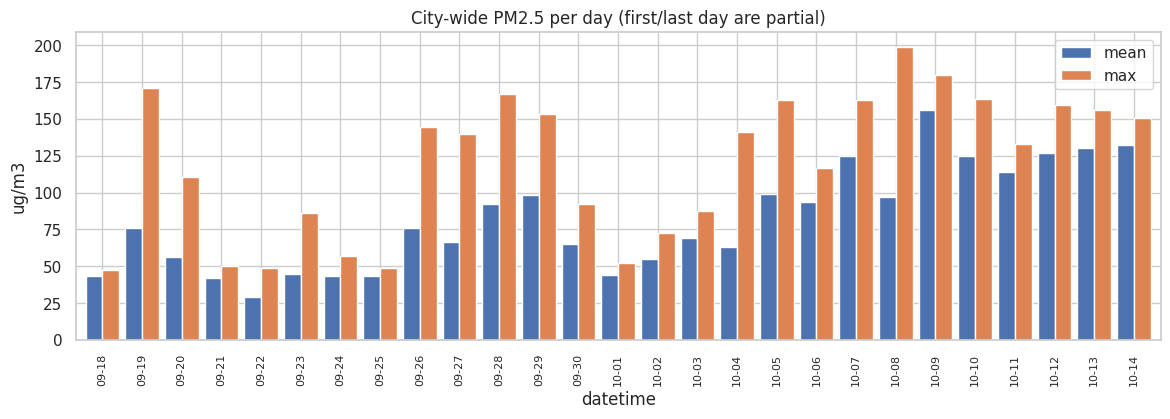

In [ ]:
daily = model["pm25_citymean"].resample("D").agg(["mean", "max", "count"])
ax = daily[["mean", "max"]].plot(kind="bar", figsize=(14, 4), width=0.85)
ax.set_xticklabels([d.strftime("%m-%d") for d in daily.index], rotation=90, fontsize=8)
ax.set_title("City-wide PM2.5 per day (first/last day are partial)"); ax.set_ylabel("ug/m3"); plt.show()

In [ ]:
# Spike definition for EDA: city-mean above its 95th percentile (illustrative; labels in Phase 3 will use TRAIN data only)
thr = model["pm25_citymean"].quantile(0.95)
spike = model["pm25_citymean"] > thr
print(f"95th percentile of city-mean PM2.5 = {thr:.1f} ug/m3  ->  {int(spike.sum())} spike hours of {len(model)}")

# Do the core stations rise together?
own_thr = model[core_pm].quantile(0.95)
above = model[core_pm] > own_thr
any_hr, all_hr = above.any(axis=1), above.all(axis=1)
print(f"Hours where >=1 core station is in its own top 5%: {int(any_hr.sum())}")
print(f"  ...of which ALL core stations are in their top 5% together: {int(all_hr.sum())} ({all_hr.sum()/max(any_hr.sum(),1)*100:.0f}%)")

ep = (spike != spike.shift()).cumsum()
episodes = (model[spike].groupby(ep[spike])["pm25_citymean"]
            .agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), peak="max"))
episodes["hours"] = (episodes["end"] - episodes["start"]).dt.total_seconds() / 3600 + 1
print(f"\n{len(episodes)} spike episodes, longest / highest first:")
display(episodes.sort_values(["peak"], ascending=False).head(10).reset_index(drop=True))

95th percentile of city-mean PM2.5 = 155.9 ug/m3  ->  31 spike hours of 615
Hours where >=1 core station is in its own top 5%: 38
  ...of which ALL core stations are in their top 5% together: 24 (63%)

10 spike episodes, longest / highest first:


,start,end,peak,hours
0,2026-10-08 22:00:00,2026-10-09 14:00:00,199.15,17.0
1,2026-09-19 12:00:00,2026-09-19 12:00:00,171.10,1.0
2,2026-09-28 22:00:00,2026-09-28 23:00:00,167.20,2.0
3,2026-10-10 09:00:00,2026-10-10 10:00:00,163.60,2.0
4,2026-10-05 19:00:00,2026-10-05 19:00:00,163.15,1.0
5,2026-10-07 14:00:00,2026-10-07 15:00:00,162.55,2.0
6,2026-09-28 16:00:00,2026-09-28 18:00:00,160.70,3.0
7,2026-10-07 22:00:00,2026-10-07 22:00:00,160.20,1.0
8,2026-10-12 13:00:00,2026-10-12 13:00:00,159.50,1.0
9,2026-10-13 11:00:00,2026-10-13 11:00:00,156.40,1.0


Overlapping hours per pair:


,Alexandra_Canal,Marina_Bay
Alexandra_Canal,615,615
Marina_Bay,615,615


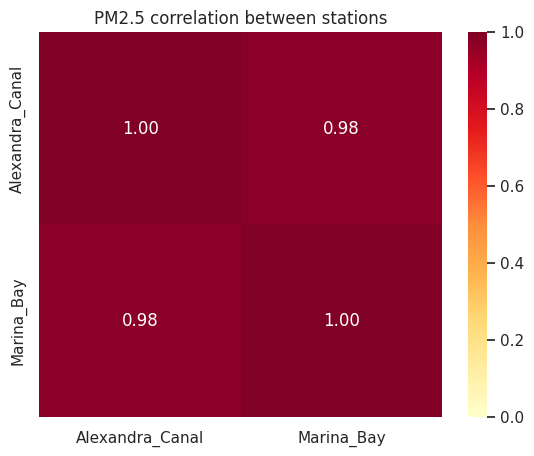

In [ ]:
# Cross-station correlation in the window
corr = model[pm_cols_model].rename(columns=lambda c: c.replace("pm25__", "")).corr()
nobs = model[pm_cols_model].rename(columns=lambda c: c.replace("pm25__", "")).notna().astype(int)
print("Overlapping hours per pair:"); display(nobs.T.dot(nobs))
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1)
plt.title("PM2.5 correlation between stations"); plt.show()

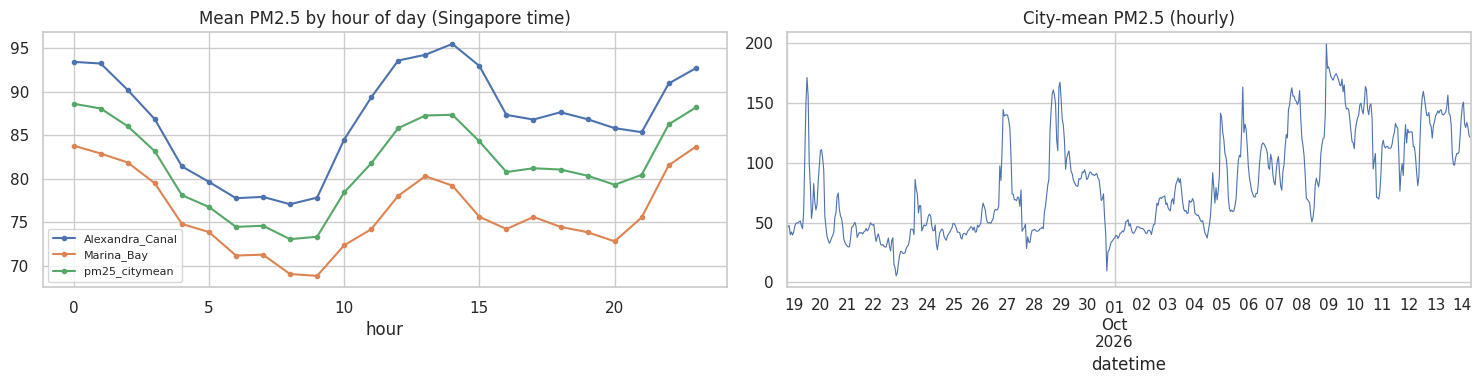

In [ ]:
# Diurnal pattern + daily profile
tmp = model.copy(); tmp["hour"] = tmp.index.hour
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for c in pm_cols_model + ["pm25_citymean"]:
    tmp.groupby("hour")[c].mean().plot(ax=axes[0], marker="o", ms=3, label=c.replace("pm25__", ""))
axes[0].set_title("Mean PM2.5 by hour of day (Singapore time)"); axes[0].legend(fontsize=8)
tmp["pm25_citymean"].plot(ax=axes[1], lw=0.8); axes[1].set_title("City-mean PM2.5 (hourly)")
plt.tight_layout(); plt.show()

In [ ]:
# Persistence preview: how strongly is PM2.5 related to its own past? (motivates Phase 3 lag features)
s = model["pm25_citymean"]
acf = pd.Series({f"lag {k}h": s.autocorr(k) for k in [1, 3, 6, 12, 24, 48]}).round(3)
print("Autocorrelation of city-mean PM2.5:"); display(acf.to_frame("autocorr"))

Autocorrelation of city-mean PM2.5:


,autocorr
lag 1h,0.966
lag 3h,0.865
lag 6h,0.725
lag 12h,0.569
lag 24h,0.490
lag 48h,0.461


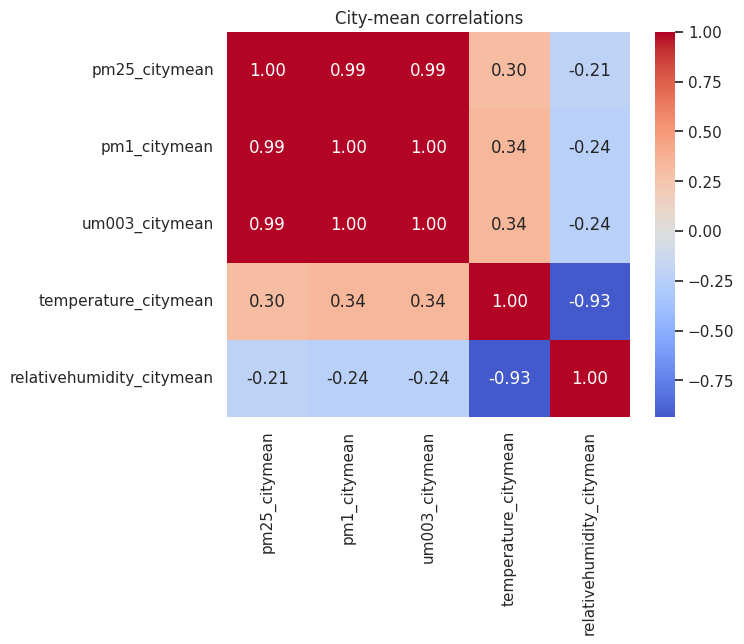

In [ ]:
# PM vs meteorology (core-station city means)
core = [c for c in ["pm25_citymean", "pm1_citymean", "um003_citymean",
                    "temperature_citymean", "relativehumidity_citymean"] if c in model.columns]
plt.figure(figsize=(6.5, 5))
sns.heatmap(model[core].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("City-mean correlations"); plt.show()

## Part 1 · 8. Save cleaned datasets for the next parts

In [ ]:
model.to_csv("clean_hourly_model.csv")           # used for Phase 3+
filled.to_csv("clean_hourly_wide_all.csv")       # full grid, all stations (reference)
print("Saved clean_hourly_model.csv    ", model.shape, f"{model.index.min()} -> {model.index.max()}")
print("Saved clean_hourly_wide_all.csv ", filled.shape)
# (intermediate CSVs are kept in the Colab file panel; Part 2 below uses them from memory)

Saved clean_hourly_model.csv     (615, 16) 2026-09-18 18:00:00 -> 2026-10-14 08:00:00
Saved clean_hourly_wide_all.csv  (754, 10)


In [ ]:
# ---- Part 1 summary (auto-generated) ----
print("=== PART 1 SUMMARY ===")
print(f"Raw files: {len(files_found)} | raw rows: {len(long_raw)} | invalid/zero values set to NaN: {int(bad.sum())}")
print(f"Full merged grid: {wide.shape[0]} hourly timestamps ({wide.index.min():%Y-%m-%d} to {wide.index.max():%Y-%m-%d})")
print(f"Core stations: {CORE_STATIONS}")
print(f"Modelling window: {MODEL_START} -> {MODEL_END} = {len(model)} hours ({len(model)/24:.1f} days)")
print(f"City-mean PM2.5: mean {model.pm25_citymean.mean():.1f}, max {model.pm25_citymean.max():.1f} ug/m3")
print(f"Share of hours above NEA 'Elevated' (>55): {(model.pm25_citymean > 55).mean()*100:.0f}%")
print(f"p95 spike threshold: {thr:.1f} ug/m3 | spike episodes: {len(episodes)}")
print(f"Autocorr lag-24h: {acf['lag 24h']} | lag-48h: {acf['lag 48h']}")

=== PART 1 SUMMARY ===
Raw files: 2 | raw rows: 6845 | invalid/zero values set to NaN: 2
Full merged grid: 754 hourly timestamps (2026-09-12 to 2026-10-14)
Core stations: ['Alexandra_Canal', 'Marina_Bay']
Modelling window: 2026-09-18 18:00:00 -> 2026-10-14 08:00:00 = 615 hours (25.6 days)
City-mean PM2.5: mean 81.6, max 199.1 ug/m3
Share of hours above NEA 'Elevated' (>55): 63%
p95 spike threshold: 155.9 ug/m3 | spike episodes: 10
Autocorr lag-24h: 0.49 | lag-48h: 0.461


---
# Part 2: Feature Engineering (Phase 3)
The cleaned hourly dataframe `model` from Part 1 is used directly.

**Input:** `model` from Part 1 (hourly, Alexandra Canal + Marina Bay, regular grid, no gaps).
**Output:** `features_all.csv` = leakage-safe features + forecast targets (+24h, +48h) + chronological split labels.

**Forecast setup.** At every *forecast origin* `t` we only use information available at or before `t`, and predict the city-wide PM2.5 at `t+24h` and `t+48h`.

| Group | Features (all computed from data up to time `t`) |
|---|---|
| Lag | city PM2.5 at t, t-1, t-3, t-6, t-12, t-24, t-48 |
| Rolling | 6h / 24h mean and std, 24h max / min |
| Change | 1h / 6h / 24h difference, deviation from 24h mean |
| Station-level | each station's current PM2.5, its t-24 value, 6h mean |
| Spatial | spread between stations (range, std, 24h mean spread) |
| Composition & meteorology | PM1, PM1/PM2.5 fine fraction, particle count (um003), temperature, humidity (current, lag, 24h mean) |
| Calendar | hour of day (sin/cos). Day of week and weekend flag are computed but kept as `aux_` columns, not used by default (section 7) |

**Skipped on purpose:** month and season indicators. The data spans less than one month, so they would be constant or just a time trend.

## Part 2 · 1. Load the cleaned data from Part 1

In [ ]:
# `model` comes straight from Part 1 (same notebook). If you run only this part, reload it from disk.
if "model" not in globals():
    model = pd.read_csv("clean_hourly_model.csv", index_col="datetime", parse_dates=True)

steps = model.index.to_series().diff().dropna().unique()
assert len(steps) == 1 and steps[0] == pd.Timedelta("1h"), f"Index is not a regular hourly grid: {steps}"
assert model["pm25_citymean"].notna().all(), "pm25_citymean has gaps"

SITES = sorted(c.split("__")[1] for c in model.columns if c.startswith("pm25__"))
for s in SITES:
    for p in ["pm25", "pm1", "um003", "temperature", "relativehumidity"]:
        assert f"{p}__{s}" in model.columns, f"missing {p}__{s}"
print("Stations:", SITES)
print("Rows:", len(model), "|", model.index.min(), "->", model.index.max())
model.iloc[:3, :8]

Stations: ['Alexandra_Canal', 'Marina_Bay']
Rows: 615 | 2026-09-18 18:00:00 -> 2026-10-14 08:00:00


,pm1__Alexandra_Canal,pm1__Marina_Bay,pm25__Alexandra_Canal,pm25__Marina_Bay,relativehumidity__Alexandra_Canal,relativehumidity__Marina_Bay,temperature__Alexandra_Canal,temperature__Marina_Bay
datetime,,,,,,,,
2026-09-18 18:00:00,28.5,28.5,46.1,44.3,54.0,52.0,30.4,30.2
2026-09-18 19:00:00,30.5,29.2,48.9,44.6,54.0,52.0,30.3,31.3
2026-09-18 20:00:00,31.8,29.1,50.3,44.4,53.0,53.0,30.0,30.5


## Part 2 · 2. Configuration
All choices are in one place. `HIGH_THR` is NEA's published 1-hour PM2.5 "High" band edge (150 ug/m3), an external fixed value, so the spike label never depends on the data split.

In [ ]:
HORIZONS = [24, 48]            # forecast horizons in hours
LAGS = [1, 3, 6, 12, 24, 48]   # lags of city-wide PM2.5 (hours)
HIGH_THR = 150                 # NEA 1-hour "High" band (>150 ug/m3), used for the spike label
TEST_FRAC, VAL_FRAC = 0.15, 0.15
PURGE = True                   # drop rows whose target window crosses a split boundary (prevents label leakage)
USE_DAY_OF_WEEK = False        # see section 7: with <4 weeks of data a weekday pattern is indistinguishable from the trend

## Part 2 · 3. Feature engineering
Every feature is a function of data up to time `t` only (`shift(k)` with k >= 0, trailing `rolling`, no centered windows, no future-looking fills). Section 5 tests this automatically.

In [ ]:
def build_features(df):
    """Feature matrix. Row t uses only data from times <= t."""
    y = df["pm25_citymean"]
    X = pd.DataFrame(index=df.index)

    # --- current level, lags (persistence & diurnal memory)
    X["pm25_now"] = y
    for k in LAGS:
        X[f"pm25_lag{k}"] = y.shift(k)

    # --- trailing rolling statistics
    for w in (6, 24):
        r = y.rolling(w, min_periods=w)
        X[f"pm25_rollmean{w}"] = r.mean()
        X[f"pm25_rollstd{w}"] = r.std()
    X["pm25_rollmax24"] = y.rolling(24, min_periods=24).max()
    X["pm25_rollmin24"] = y.rolling(24, min_periods=24).min()

    # --- change / momentum
    X["pm25_diff1"] = y.diff(1)
    X["pm25_diff6"] = y.diff(6)
    X["pm25_diff24"] = y.diff(24)
    X["pm25_vs_roll24"] = y - X["pm25_rollmean24"]

    # --- station level
    for s in SITES:
        p = df[f"pm25__{s}"]
        X[f"pm25_{s}_now"] = p
        X[f"pm25_{s}_lag24"] = p.shift(24)
        X[f"pm25_{s}_rollmean6"] = p.rolling(6, min_periods=6).mean()

    # --- spatial aggregation / variation between stations
    st = df[[f"pm25__{s}" for s in SITES]]
    X["spatial_range"] = st.max(axis=1) - st.min(axis=1)
    X["spatial_std"] = st.std(axis=1)
    X["spatial_range_roll24"] = X["spatial_range"].rolling(24, min_periods=24).mean()

    # --- composition & meteorology (city means from Part 1)
    X["pm1_now"] = df["pm1_citymean"]
    X["fine_fraction"] = df["pm1_citymean"] / y            # PM1 / PM2.5: share of very fine particles
    X["um003_now"] = df["um003_citymean"]
    X["um003_lag24"] = df["um003_citymean"].shift(24)
    X["temp_now"] = df["temperature_citymean"]
    X["temp_rollmean24"] = df["temperature_citymean"].rolling(24, min_periods=24).mean()
    X["rh_now"] = df["relativehumidity_citymean"]
    X["rh_rollmean24"] = df["relativehumidity_citymean"].rolling(24, min_periods=24).mean()
    X["rh_diff6"] = df["relativehumidity_citymean"].diff(6)

    # --- calendar (Singapore local time; same clock hour at t+24h and t+48h)
    hr = df.index.hour
    X["hour_sin"] = np.sin(2 * np.pi * hr / 24)
    X["hour_cos"] = np.cos(2 * np.pi * hr / 24)
    X["dow"] = df.index.dayofweek
    X["is_weekend"] = (df.index.dayofweek >= 5).astype(int)
    return X

F = build_features(model)
if not USE_DAY_OF_WEEK:   # keep the columns for reference, but mark them as auxiliary (not model inputs)
    F = F.rename(columns={"dow": "aux_dow", "is_weekend": "aux_is_weekend"})
print("Feature matrix:", F.shape)
print("Max NaN count in any feature (from the lag/rolling warm-up):", int(F.isna().sum().max()))

Feature matrix: (615, 39)
Max NaN count in any feature (from the lag/rolling warm-up): 48


## Part 2 · 4. Targets, spike labels and the modelling table
- `target_h24` / `target_h48`: city-wide PM2.5 at `t+24h` / `t+48h` (regression targets).
- `high_h24` / `high_h48`: 1 if that future value exceeds the NEA "High" threshold (150 ug/m3), for the early-warning use case.
- Warm-up rows (first 48 hours, where lags do not exist yet) are dropped. The last `h` rows have no target for horizon `h`.

In [ ]:
T = pd.DataFrame(index=model.index)
for h in HORIZONS:
    T[f"target_h{h}"] = model["pm25_citymean"].shift(-h)
    T[f"high_h{h}"] = (T[f"target_h{h}"] > HIGH_THR).astype(float).where(T[f"target_h{h}"].notna())

data = F.join(T)
FEATURES = [c for c in F.columns if not c.startswith("aux_")]   # model inputs; aux_* columns are excluded
n0 = len(data)
data = data.dropna(subset=list(F.columns))
print(f"Rows: {n0} -> {len(data)} (dropped {n0 - len(data)} warm-up rows)")
print("Features:", len(FEATURES))
print("Rows with a target -> " + ", ".join(f"h{h}: {int(data[f'target_h{h}'].notna().sum())}" for h in HORIZONS))
data[["pm25_now", "pm25_lag24", "pm25_rollmean24", "target_h24", "target_h48", "high_h24"]].tail(4)

Rows: 615 -> 567 (dropped 48 warm-up rows)
Features: 37
Rows with a target -> h24: 543, h48: 519


,pm25_now,pm25_lag24,pm25_rollmean24,target_h24,target_h48,high_h24
datetime,,,,,,
2026-10-14 05:00:00,129.80,144.25,128.827083,NaN,NaN,NaN
2026-10-14 06:00:00,122.80,140.15,128.104167,NaN,NaN,NaN
2026-10-14 07:00:00,121.00,139.90,127.316667,NaN,NaN,NaN
2026-10-14 08:00:00,121.35,141.00,126.497917,NaN,NaN,NaN


## Part 2 · 5. Leakage tests
1. **Features use only the past:** for random forecast origins `t`, rebuild the features from data truncated at `t`. The row for `t` must be identical to the one built from the full series. If any feature used future data the two would differ.
2. **Targets are aligned:** `target_hH` at `t` must equal the observed city PM2.5 at `t+H`.

In [ ]:
def leakage_check(n_checks=25, seed=0):
    rng = np.random.default_rng(seed)
    full = build_features(model)
    cand = full.dropna().index
    picks = rng.choice(len(cand), size=min(n_checks, len(cand)), replace=False)
    leaks = []
    for i in picks:
        t = cand[i]
        trunc = build_features(model.loc[:t])
        if not np.allclose(trunc.loc[t].values.astype(float), full.loc[t].values.astype(float), equal_nan=True):
            leaks.append(t)
    return leaks

leaks = leakage_check()
assert not leaks, f"Future information leaks into features at: {leaks[:5]}"
print("Test 1 passed: features at t identical when all data after t is removed (25 random origins).")

for h in HORIZONS:
    d = data[data[f"target_h{h}"].notna()]
    sample = d.index[::37]
    ok = np.allclose(d.loc[sample, f"target_h{h}"].values, model["pm25_citymean"].reindex(sample + pd.Timedelta(hours=h)).values)
    assert ok, f"target_h{h} misaligned"
print("Test 2 passed: targets equal PM2.5 observed H hours later.")

Test 1 passed: features at t identical when all data after t is removed (25 random origins).
Test 2 passed: targets equal PM2.5 observed H hours later.


## Part 2 · 6. Chronological train / validation / test split (no shuffling)
Rows are ordered in time. The test set is the **last 15%**, validation the 15% before it, and training everything earlier.

**Purging:** the target of a row at time `t` is the value at `t+h`. Without a gap, the last training rows would have targets lying *inside* the validation period (and validation targets inside the test period), which leaks information across splits. With `PURGE=True` we drop `h` rows before each boundary. The cost is visible in the table below.

**Watch the `target_mean` column:** if the PM2.5 level differs a lot between train and validation/test, models trained on the early period must extrapolate to levels they barely saw. That matters for model choice in Part 3.

In [ ]:
def make_split(idx, h, test_frac=TEST_FRAC, val_frac=VAL_FRAC, purge=PURGE):
    n = len(idx); gap = h if purge else 0
    n_test, n_val = int(round(test_frac * n)), int(round(val_frac * n))
    test_start = n - n_test
    val_end = test_start - gap
    val_start = val_end - n_val
    train_end = val_start - gap
    s = pd.Series("purged", index=idx)
    s.iloc[:train_end] = "train"
    s.iloc[val_start:val_end] = "val"
    s.iloc[test_start:] = "test"
    return s

for h in HORIZONS:
    rows = data.index[data[f"target_h{h}"].notna()]
    assert (rows.to_series().diff().dropna() == pd.Timedelta("1h")).all()
    sp = make_split(rows, h)
    data[f"split_h{h}"] = sp.reindex(data.index).fillna("no_target")
    tr, va, te = (sp.index[sp == k] for k in ("train", "val", "test"))
    if PURGE:   # label windows must not cross split boundaries
        assert tr.max() + pd.Timedelta(hours=h) < va.min() and va.max() + pd.Timedelta(hours=h) < te.min()
    assert tr.max() < va.min() and va.max() < te.min()

rows_out = []
for h in HORIZONS:
    for k in ["train", "val", "test", "purged"]:
        d = data[data[f"split_h{h}"] == k]
        rows_out.append({"horizon": f"+{h}h", "split": k, "rows": len(d),
                         "from": d.index.min(), "to": d.index.max(),
                         "target_mean": d[f"target_h{h}"].mean(), "target_max": d[f"target_h{h}"].max(),
                         "high_hours(>150)": int(d[f"high_h{h}"].sum())})
split_table = pd.DataFrame(rows_out).round(1)
display(split_table)
for h in HORIZONS:
    m = split_table[split_table.horizon == f"+{h}h"].set_index("split")["target_mean"]
    print(f"+{h}h mean target: train {m['train']} | val {m['val']} | test {m['test']}  (large gaps = regime shift)")

,horizon,split,rows,from,to,target_mean,target_max,high_hours(>150)
0,+24h,train,333,2026-09-20 18:00:00,2026-10-04 14:00:00,61.6,167.2,6
1,+24h,val,81,2026-10-05 15:00:00,2026-10-08 23:00:00,123.2,199.1,25
2,+24h,test,81,2026-10-10 00:00:00,2026-10-13 08:00:00,124.4,159.5,5
3,+24h,purged,48,2026-10-04 15:00:00,2026-10-09 23:00:00,113.4,163.6,3
4,+48h,train,267,2026-09-20 18:00:00,2026-10-01 20:00:00,62.2,167.2,6
5,+48h,val,78,2026-10-03 21:00:00,2026-10-07 02:00:00,108.7,199.1,13
6,+48h,test,78,2026-10-09 03:00:00,2026-10-12 08:00:00,124.8,159.5,5
7,+48h,purged,96,2026-10-01 21:00:00,2026-10-09 02:00:00,107.1,174.2,15


+24h mean target: train 61.6 | val 123.2 | test 124.4  (large gaps = regime shift)
+48h mean target: train 62.2 | val 108.7 | test 124.8  (large gaps = regime shift)


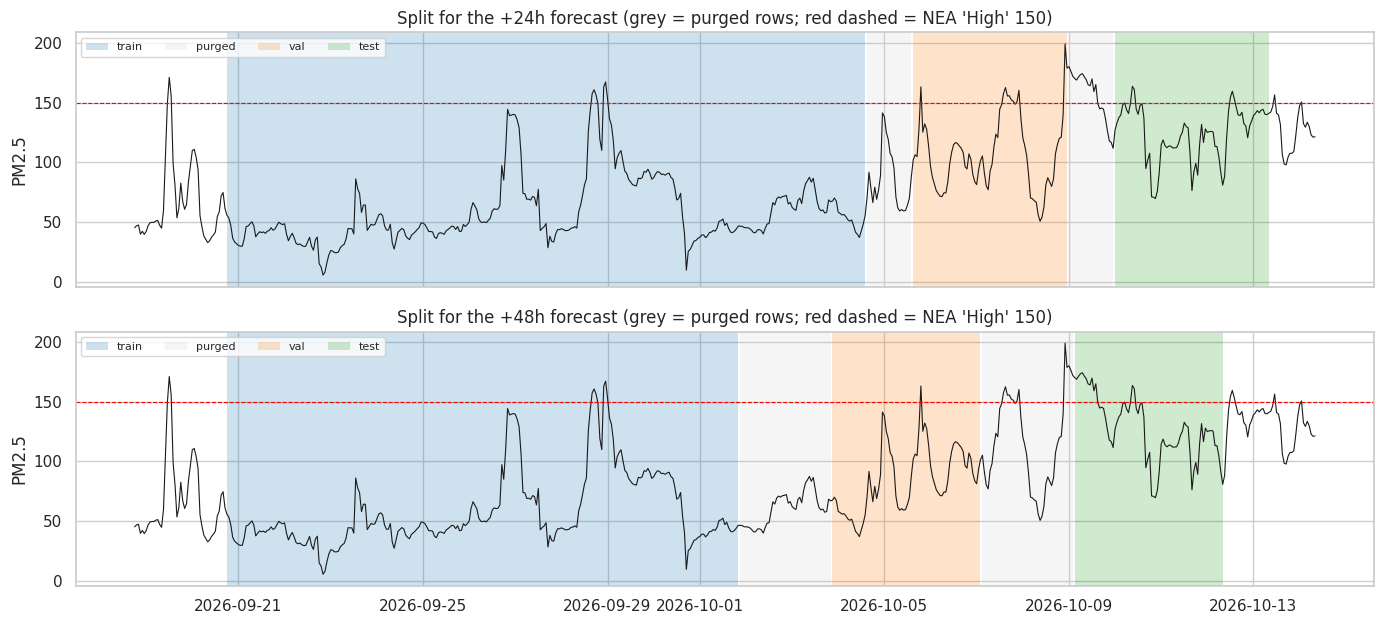

In [ ]:
def runs(s):
    grp = (s != s.shift()).cumsum()
    for _, g in s.groupby(grp):
        yield g.iloc[0], g.index[0], g.index[-1]

colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green", "purged": "lightgrey"}
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 3.2 * len(HORIZONS)), sharex=True)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    ax.plot(model.index, model["pm25_citymean"], color="k", lw=0.8)
    for lab, a, b in runs(data[f"split_h{h}"]):
        if lab in colors:
            ax.axvspan(a, b, color=colors[lab], alpha=0.22, lw=0, label=lab)
    ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    h_, l_ = ax.get_legend_handles_labels(); uniq = dict(zip(l_, h_))
    ax.legend(uniq.values(), uniq.keys(), ncol=4, fontsize=8, loc="upper left")
    ax.set_title(f"Split for the +{h}h forecast (grey = purged rows; red dashed = NEA 'High' 150)")
    ax.set_ylabel("PM2.5")
plt.tight_layout(); plt.show()

## Part 2 · 7. Feature groups and train-only relationships
Relationships with the target are examined on the **training rows only**, so nothing about the validation or test periods influences feature decisions.

In [ ]:
def group_of(c):
    if c.startswith("hour_"): return "calendar"
    if c.startswith("spatial"): return "spatial"
    if any(c.startswith(f"pm25_{s}_") for s in SITES): return "station-level"
    if c in ("pm25_now", "pm25_diff1", "pm25_diff6", "pm25_diff24", "pm25_vs_roll24"): return "level & change"
    if "_lag" in c: return "lag"
    if "_roll" in c: return "rolling"
    return "composition & meteorology"

groups = pd.Series({c: group_of(c) for c in FEATURES})
display(groups.value_counts().rename("n_features").to_frame())
for g, cols in groups.groupby(groups):
    print(f"{g:27s}", ", ".join(cols.index))

,n_features
rolling,8
lag,7
station-level,6
composition & meteorology,6
level & change,5
spatial,3
calendar,2


calendar                    hour_sin, hour_cos
composition & meteorology   pm1_now, fine_fraction, um003_now, temp_now, rh_now, rh_diff6
lag                         pm25_lag1, pm25_lag3, pm25_lag6, pm25_lag12, pm25_lag24, pm25_lag48, um003_lag24
level & change              pm25_now, pm25_diff1, pm25_diff6, pm25_diff24, pm25_vs_roll24
rolling                     pm25_rollmean6, pm25_rollstd6, pm25_rollmean24, pm25_rollstd24, pm25_rollmax24, pm25_rollmin24, temp_rollmean24, rh_rollmean24
spatial                     spatial_range, spatial_std, spatial_range_roll24
station-level               pm25_Alexandra_Canal_now, pm25_Alexandra_Canal_lag24, pm25_Alexandra_Canal_rollmean6, pm25_Marina_Bay_now, pm25_Marina_Bay_lag24, pm25_Marina_Bay_rollmean6


### Feature dictionary
What each input means in plain words, and why it can help forecast PM2.5 a day or two ahead.

In [ ]:
import re
STATIC = {
    "pm25_now": ("City-wide PM2.5 at the forecast origin", "Haze persists for hours to days, so the current level is the strongest starting point"),
    "pm25_rollmax24": ("Highest city PM2.5 in the last 24 h", "Recent peak: tells whether a spike just happened"),
    "pm25_rollmin24": ("Lowest city PM2.5 in the last 24 h", "Recent floor: how clean the air got"),
    "pm25_diff1": ("Change in city PM2.5 over the last 1 h", "Momentum: is the haze building or clearing right now"),
    "pm25_diff6": ("Change in city PM2.5 over the last 6 h", "Medium-term trend"),
    "pm25_diff24": ("Change in city PM2.5 over the last 24 h", "Day-on-day trend: is each day worse than the last"),
    "pm25_vs_roll24": ("Current PM2.5 minus its 24 h average", "How far above or below the recent baseline (anomaly)"),
    "spatial_range": ("Highest minus lowest station PM2.5 now", "Large gap = local effects / sheltering; small gap = region-wide haze"),
    "spatial_std": ("Standard deviation across stations now", "Same idea as the range, less sensitive to one sensor"),
    "spatial_range_roll24": ("Average station gap over the last 24 h", "Persistent local differences vs. a uniform haze blanket"),
    "pm1_now": ("City-wide PM1 (finest particles)", "Smoke is made mostly of very fine particles"),
    "fine_fraction": ("PM1 / PM2.5 ratio", "High share of fine particles points to combustion smoke rather than dust or coarse sources"),
    "um003_now": ("Particle count (0.3 um and larger) per cm3", "Counts particles instead of weighing them, so it reacts early to a new plume"),
    "um003_lag24": ("Particle count 24 h earlier", "Same hour yesterday"),
    "temp_now": ("City-wide temperature now", "Weather context: affects mixing and the sensors' readings"),
    "temp_rollmean24": ("Average temperature over the last 24 h", "Smoothed weather context (cloud / rain / heat)"),
    "rh_now": ("City-wide relative humidity now", "Humid air and rain wash out or swell particles; also a sensor bias to be aware of"),
    "rh_rollmean24": ("Average humidity over the last 24 h", "Smoothed weather context"),
    "rh_diff6": ("Change in humidity over the last 6 h", "Fronts and showers show up as humidity jumps"),
    "hour_sin": ("Hour of day, sine part", "Daily cycle (traffic, boundary-layer height); sine/cosine pair avoids a jump at midnight"),
    "hour_cos": ("Hour of day, cosine part", "Pairs with hour_sin"),
}
def describe(c):
    if c in STATIC: return STATIC[c]
    m = re.fullmatch(r"pm25_lag(\d+)", c)
    if m:
        k = int(m.group(1))
        return (f"City PM2.5 {k} h before the origin",
                "Same hour yesterday / the day before: daily pattern and multi-day haze persistence" if k in (24, 48)
                else "Recent history: short-term persistence and trend")
    m = re.fullmatch(r"pm25_rollmean(\d+)", c)
    if m: return (f"Average city PM2.5 over the last {m.group(1)} h", "Smooths sensor noise; shows the recent baseline")
    m = re.fullmatch(r"pm25_rollstd(\d+)", c)
    if m: return (f"Standard deviation of city PM2.5 over the last {m.group(1)} h", "Volatility: unsettled air often accompanies spikes")
    m = re.fullmatch(r"pm25_(.+)_(now|lag24|rollmean6)", c)
    if m:
        name, kind = m.group(1).replace("_", " "), m.group(2)
        return ({"now": f"PM2.5 at {name} now", "lag24": f"PM2.5 at {name} 24 h earlier", "rollmean6": f"PM2.5 at {name}, last-6 h average"}[kind],
                "Station-level detail: lets a model weigh a sensor that sees the haze first")
    raise KeyError(f"no description for {c}")

fd = pd.DataFrame({c: (groups[c], *describe(c)) for c in FEATURES}, index=["group", "what it is", "why it may help"]).T
fd = fd.sort_values("group", kind="stable")
assert len(fd) == len(FEATURES)
nonpm = [c for c in FEATURES if c.startswith(("pm1", "fine", "um003", "temp", "rh"))]
print(f"{len(nonpm)} of {len(FEATURES)} features come from the other sensors (PM1, particle count, temperature, humidity):")
print("  ", ", ".join(nonpm))
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 95, "display.width", 250):
    display(fd)

9 of 37 features come from the other sensors (PM1, particle count, temperature, humidity):
   pm1_now, fine_fraction, um003_now, um003_lag24, temp_now, temp_rollmean24, rh_now, rh_rollmean24, rh_diff6


,group,what it is,why it may help
hour_sin,calendar,"Hour of day, sine part","Daily cycle (traffic, boundary-layer height); sine/cosine pair avoids a jump at midnight"
hour_cos,calendar,"Hour of day, cosine part",Pairs with hour_sin
pm1_now,composition & meteorology,City-wide PM1 (finest particles),Smoke is made mostly of very fine particles
fine_fraction,composition & meteorology,PM1 / PM2.5 ratio,High share of fine particles points to combustion smoke rather than dust or coarse sources
um003_now,composition & meteorology,Particle count (0.3 um and larger) per cm3,"Counts particles instead of weighing them, so it reacts early to a new plume"
temp_now,composition & meteorology,City-wide temperature now,Weather context: affects mixing and the sensors' readings
rh_now,composition & meteorology,City-wide relative humidity now,Humid air and rain wash out or swell particles; also a sensor bias to be aware of
rh_diff6,composition & meteorology,Change in humidity over the last 6 h,Fronts and showers show up as humidity jumps
pm25_lag1,lag,City PM2.5 1 h before the origin,Recent history: short-term persistence and trend
pm25_lag3,lag,City PM2.5 3 h before the origin,Recent history: short-term persistence and trend


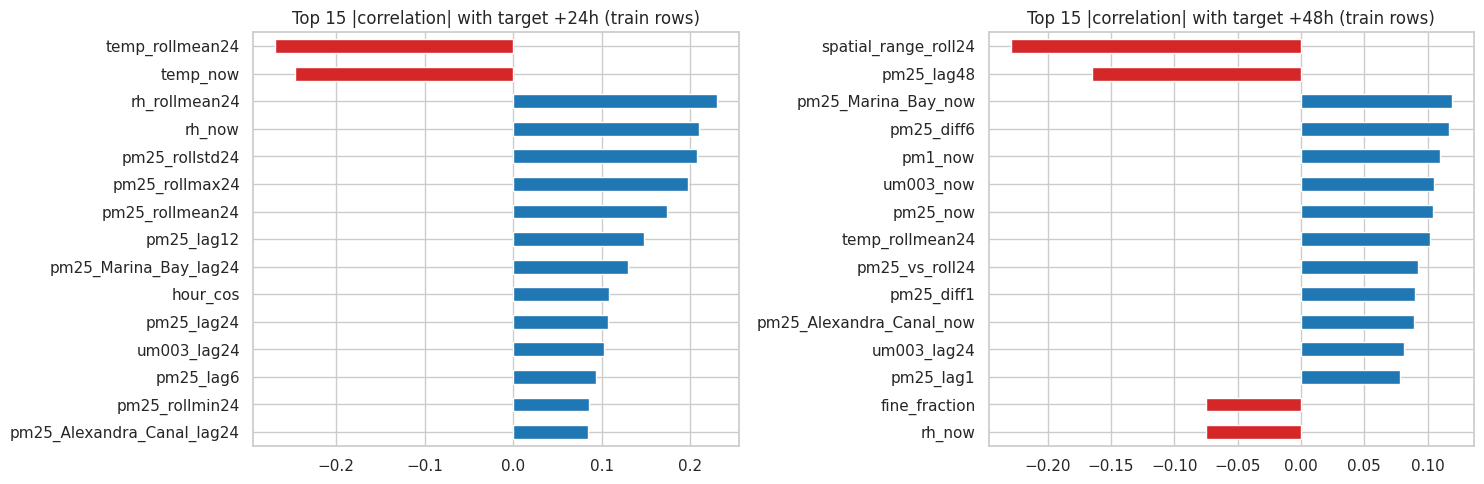

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 5))
for ax, h in zip(axes, HORIZONS):
    tr = data[data[f"split_h{h}"] == "train"]
    corr = tr[FEATURES].corrwith(tr[f"target_h{h}"]).sort_values(key=abs, ascending=False).head(15)[::-1]
    corr.plot.barh(ax=ax, color=["tab:red" if v < 0 else "tab:blue" for v in corr])
    ax.set_title(f"Top 15 |correlation| with target +{h}h (train rows)")
plt.tight_layout(); plt.show()

**Why day-of-week is not a model input.** It ranks high in the correlations above, but the training period is only about two weeks, so each weekday occurs on just 2 to 3 distinct dates. Any weekday "effect" is therefore the haze trend lining up with the calendar, not a real weekly cycle. Hour of day, which repeats every day, is kept.

In [ ]:
tr = data[data["split_h24"] == "train"]
chk = tr.groupby("aux_dow")["target_h24"].agg(mean_target="mean", hours="count").round(1)
chk["distinct_dates"] = tr.groupby("aux_dow").apply(lambda d: d.index.normalize().nunique())
chk.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][:len(chk)] if len(chk) == 7 else chk.index
display(chk)

,mean_target,hours,distinct_dates
Mon,63.8,48,2
Tue,55.1,48,2
Wed,43.5,48,2
Thu,49.1,48,2
Fri,72.6,48,2
Sat,64.5,48,2
Sun,83.8,45,3


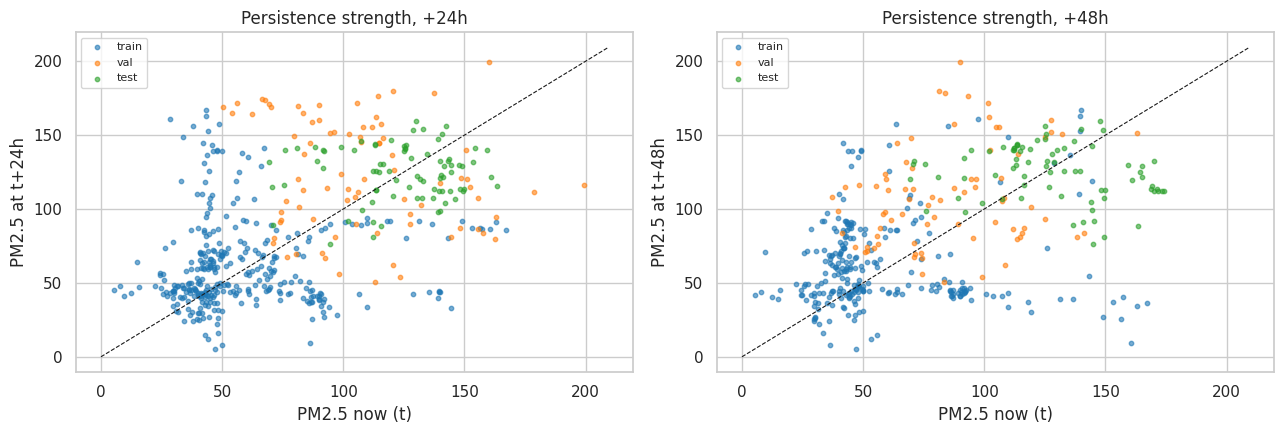

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 4.5))
for ax, h in zip(axes, HORIZONS):
    for k in ["train", "val", "test"]:
        d = data[data[f"split_h{h}"] == k]
        ax.scatter(d["pm25_now"], d[f"target_h{h}"], s=10, alpha=0.6, color=colors[k], label=k)
    lim = [0, data["pm25_now"].max() * 1.05]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlabel("PM2.5 now (t)"); ax.set_ylabel(f"PM2.5 at t+{h}h")
    ax.set_title(f"Persistence strength, +{h}h"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Does the spatial spread or fine fraction change during high-PM episodes? (train rows, h=24)
tr = data[data["split_h24"] == "train"]
cmp = tr.groupby(tr["pm25_now"] > HIGH_THR)[["spatial_range", "fine_fraction", "um003_now", "rh_now", "temp_now"]].mean().round(2)
cmp.index = ["PM2.5 now <= 150", "PM2.5 now > 150"][:len(cmp)] if len(cmp) == 2 else cmp.index
display(cmp)

,spatial_range,fine_fraction,um003_now,rh_now,temp_now
PM2.5 now <= 150,7.33,0.58,2245.49,59.73,29.24
PM2.5 now > 150,18.68,0.49,6040.00,62.83,28.65


## Part 2 · 8. Sanity baselines (preview of Phase 4)
Simple reference forecasts show what any model must beat. For a +24h or +48h horizon the "seasonal naive" forecast (same hour one or two days earlier) is identical to persistence of the current value, because 24 and 48 are whole numbers of days. Formal baseline and model evaluation happens in Part 3.

In [ ]:
rows_out = []
for h in HORIZONS:
    tr = data[data[f"split_h{h}"] == "train"]
    train_mean = tr[f"target_h{h}"].mean()
    for sp in ["val", "test"]:
        d = data[data[f"split_h{h}"] == sp]
        y = d[f"target_h{h}"]
        preds = {"persistence (value now)": d["pm25_now"],
                 "24h trailing mean": d["pm25_rollmean24"],
                 "train mean": pd.Series(train_mean, index=d.index)}
        for name, p in preds.items():
            rows_out.append({"horizon": f"+{h}h", "split": sp, "baseline": name,
                             "RMSE": np.sqrt(((y - p) ** 2).mean()), "MAE": (y - p).abs().mean()})
display(pd.DataFrame(rows_out).round(1).pivot_table(index=["horizon", "baseline"], columns="split", values=["RMSE", "MAE"]).round(1))

MAE        RMSE      
split                            test   val  test   val
horizon baseline                                       
+24h    24h trailing mean        22.9  31.9  26.5  37.2
        persistence (value now)  24.0  46.2  28.2  55.3
        train mean               62.9  62.2  65.4  71.9
+48h    24h trailing mean        22.5  36.8  29.1  43.8
        persistence (value now)  29.9  37.1  35.7  44.5
        train mean               62.6  47.2  65.2  57.5

## Part 2 · 9. Save the modelling table

In [ ]:
out = data.copy()
out.index.name = "datetime"
out.to_csv("features_all.csv")
print("Saved features_all.csv", out.shape)
print("Feature columns:", len(FEATURES), "| other columns:", [c for c in out.columns if c not in FEATURES])
try:
    from google.colab import files
    files.download("features_all.csv")
except Exception:
    pass

Saved features_all.csv (567, 45)
Feature columns: 37 | other columns: ['aux_dow', 'aux_is_weekend', 'target_h24', 'high_h24', 'target_h48', 'high_h48', 'split_h24', 'split_h48']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=== PART 2 SUMMARY ===")
print(f"Features: {len(FEATURES)} in {groups.nunique()} groups | modelling rows: {len(data)} (after {n0 - len(data)} warm-up rows)")
for h in HORIZONS:
    c = data[f"split_h{h}"].value_counts()
    print(f"+{h}h  train {c.get('train',0)} | val {c.get('val',0)} | test {c.get('test',0)} | purged {c.get('purged',0)} | no target {c.get('no_target',0)}"
          f" | high-hours in test: {int(data.loc[data[f'split_h{h}']=='test', f'high_h{h}'].sum())}")
print("Leakage tests: passed")

=== PART 2 SUMMARY ===
Features: 37 in 7 groups | modelling rows: 567 (after 48 warm-up rows)
+24h  train 333 | val 81 | test 81 | purged 48 | no target 24 | high-hours in test: 5
+48h  train 267 | val 78 | test 78 | purged 96 | no target 48 | high-hours in test: 5
Leakage tests: passed


**Next: Part 3 = Phase 4 baseline and candidate models** (naive / seasonal naive, SARIMAX, Holt-Winters, LightGBM or XGBoost), evaluated on the split labels saved in `features_all.csv`.

---
# Part 3: Baselines and Candidate Models (Phase 4)

**Evaluation protocol (same for every model)**
- For each horizon `h` (+24h, +48h) and each forecast origin `t` in the validation or test period, the model may use data **up to `t` only** and must predict the city-wide PM2.5 at `t+h`.
- Every model is trained / fitted on the **training rows only** (the split from Part 2). Validation is used to compare models; the **test set is only reported, never used to choose anything**.
- Metrics: RMSE and MAE (primary), MAPE (valid here because PM2.5 is never zero after cleaning), and *skill vs naive* = 1 - RMSE / RMSE(naive). Positive skill means better than naive.

**Models**

| Type | Model | Notes |
|---|---|---|
| Baseline | Naive: y(t+h) = y(t) | For h = 24 and 48 the *seasonal naive* forecast (same hour 1 or 2 days earlier than the target) is exactly this same value, so one row covers both |
| Baseline | 24h moving average | Stronger reference than naive when the series is noisy |
| Classical | SARIMAX(1,1,1) + daily cycle | Hour-of-day sine/cosine as exogenous inputs, parameters fitted on train, then applied to the data up to each origin (no refit) |
| Exp. smoothing | Holt-Winters | Damped additive trend, additive daily seasonality (24h), smoothing parameters fitted on train |
| ML | LightGBM, three variants | (a) PM2.5 level and (b) change from now, both with all 37 features; (c) **scale-free**: ten ratio-type features, predicting the log of the ratio y(t+h) / y(t) |
| ML (extra) | Ridge, scale-free | Same ten features and target as (c); a very low-variance linear model for small data |

In [ ]:
!pip -q install lightgbm statsmodels scikit-learn
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y = model["pm25_citymean"].asfreq("h")      # full hourly city-wide series from Part 1
H = pd.Timedelta(hours=1)

def split_idx(h, sp):
    return data.index[data[f"split_h{h}"] == sp]

def eval_idx(h):
    return data.index[data[f"split_h{h}"].isin(["val", "test"])]

def actual(h, idx):
    return data.loc[idx, f"target_h{h}"]

preds = {h: {} for h in HORIZONS}     # preds[h][model name] = Series indexed by forecast origin (val + test)
fitted = {}                           # fitted ML models, kept for interpretation in a later part
print("Horizons:", HORIZONS, "| features for ML models:", len(FEATURES))

Horizons: [24, 48] | features for ML models: 37


## Part 3 · 1. Baselines

In [ ]:
for h in HORIZONS:
    ix = eval_idx(h)
    preds[h]["Naive (y_t)"] = data.loc[ix, "pm25_now"]
    preds[h]["24h moving average"] = data.loc[ix, "pm25_rollmean24"]
print({h: list(v) for h, v in preds.items()})

{24: ['Naive (y_t)', '24h moving average'], 48: ['Naive (y_t)', '24h moving average']}


## Part 3 · 2. SARIMAX (classical)
Fitted once on the training period (the series up to the last training label). For each forecast origin the *same parameters* are applied to the data up to that origin, and a forecast `h` steps ahead is produced. This mimics operation: the model is not re-estimated on validation/test information.

In [ ]:
def hour_exog(idx):
    hr = np.asarray(idx.hour)
    return pd.DataFrame({"hr_sin": np.sin(2 * np.pi * hr / 24), "hr_cos": np.cos(2 * np.pi * hr / 24)}, index=idx)

SARIMAX_ORDER = (1, 1, 1)
t0 = time.time()
for h in HORIZONS:
    fit_end = split_idx(h, "train").max() + h * H           # last training label time (< validation start)
    y_fit = y.loc[:fit_end]
    base = SARIMAX(y_fit, exog=hour_exog(y_fit.index), order=SARIMAX_ORDER).fit(disp=False)
    out = {}
    for t in eval_idx(h):
        yt = y.loc[:t]
        r = base.apply(yt, exog=hour_exog(yt.index), refit=False)
        fut = pd.date_range(t + H, periods=h, freq="h")
        out[t] = float(r.forecast(steps=h, exog=hour_exog(fut)).iloc[-1])
    preds[h]["SARIMAX(1,1,1)+daily cycle"] = pd.Series(out).clip(lower=0)
    print(f"+{h}h SARIMAX done: AIC on train {base.aic:.0f}, params {dict(base.params.round(3))}")
print(f"{time.time() - t0:.0f}s")

+24h SARIMAX done: AIC on train 3008, params {'hr_sin': np.float64(-3.45), 'hr_cos': np.float64(3.347), 'ar.L1': np.float64(0.155), 'ma.L1': np.float64(0.114), 'sigma2': np.float64(97.892)}
+48h SARIMAX done: AIC on train 2683, params {'hr_sin': np.float64(-2.928), 'hr_cos': np.float64(1.149), 'ar.L1': np.float64(0.172), 'ma.L1': np.float64(0.1), 'sigma2': np.float64(94.115)}
18s


## Part 3 · 3. Holt-Winters exponential smoothing
Damped additive trend with additive daily seasonality (24 h). The smoothing parameters are fitted on the training period; for each origin the filter is run over the data up to that origin with those parameters fixed.

In [ ]:
HW_KW = dict(trend="add", damped_trend=True, seasonal="add", seasonal_periods=24)
def hw_param(res, *names):
    for n in names:
        if n in res.params and res.params[n] is not None:
            return float(res.params[n])
    raise KeyError(names)

t0 = time.time()
for h in HORIZONS:
    fit_end = split_idx(h, "train").max() + h * H
    hw0 = ExponentialSmoothing(y.loc[:fit_end], initialization_method="estimated", **HW_KW).fit()
    prm = dict(smoothing_level=hw_param(hw0, "smoothing_level"),
               smoothing_trend=hw_param(hw0, "smoothing_trend", "smoothing_slope"),
               smoothing_seasonal=hw_param(hw0, "smoothing_seasonal"),
               damping_trend=hw_param(hw0, "damping_trend", "damping_slope"))
    out = {}
    for t in eval_idx(h):
        m = ExponentialSmoothing(y.loc[:t], initialization_method="heuristic", **HW_KW).fit(optimized=False, **prm)
        out[t] = float(m.forecast(h).iloc[-1])
    preds[h]["Holt-Winters (damped, s=24)"] = pd.Series(out).clip(lower=0)
    print(f"+{h}h Holt-Winters done: " + ", ".join(f"{k}={v:.3f}" for k, v in prm.items()))
print(f"{time.time() - t0:.0f}s")

+24h Holt-Winters done: smoothing_level=1.000, smoothing_trend=0.099, smoothing_seasonal=0.000, damping_trend=0.800
+48h Holt-Winters done: smoothing_level=1.000, smoothing_trend=0.116, smoothing_seasonal=0.000, damping_trend=0.800
11s


## Part 3 · 4. Machine learning: LightGBM and Ridge
Default (untuned) settings; tuning is Phase 5. Ridge standardises features with **training rows only** (inside the pipeline).

**Why three variants?** The training period is much calmer than validation and test (mean about 62 vs about 124 ug/m3), so any model built on absolute levels has to extrapolate. Variants (a) and (b) use all 37 absolute-level features and show what happens. Variant (c) was designed **after seeing that failure, using validation data only**: ten **scale-free** features (seven ratios to the 24 h mean: now, 6 h mean, lag-24, lag-48, 24 h max, 6 h change, 24 h std; plus PM1/PM2.5 and hour of day) and a target that is the **log of the ratio** y(t+h) / y(t). Ratios behave the same at 60 or 120 ug/m3. Because this design was guided by validation results, validation scores for (c) are slightly optimistic. The test set played no role.

In [ ]:
LGB_PARAMS = dict(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                  random_state=42, verbose=-1)
make_lgb = lambda: lgb.LGBMRegressor(**LGB_PARAMS)
make_ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=100.0))

# scale-free feature set (every column is a ratio or a bounded quantity, so it means the same at any PM2.5 level)
XA = data[FEATURES]
ma24 = data["pm25_rollmean24"]
XR = pd.DataFrame({
    "rel_now_ma24":   data["pm25_now"] / ma24,
    "rel_ma6_ma24":   data["pm25_rollmean6"] / ma24,
    "rel_lag24_ma24": data["pm25_lag24"] / ma24,
    "rel_lag48_ma24": data["pm25_lag48"] / ma24,
    "rel_max24_ma24": data["pm25_rollmax24"] / ma24,
    "rel_diff6_ma24": data["pm25_diff6"] / ma24,
    "cv24":           data["pm25_rollstd24"] / ma24,
    "fine_fraction":  data["fine_fraction"],
    "hour_sin":       data["hour_sin"],
    "hour_cos":       data["hour_cos"],
})
assert XR.notna().all().all() and np.isfinite(XR.values).all()

def fit_ml(h, make, mode, X):
    tr = data[data[f"split_h{h}"] == "train"]
    ix = eval_idx(h)
    ytr, now_tr, now_ev = tr[f"target_h{h}"], tr["pm25_now"], data.loc[ix, "pm25_now"]
    z = {"level": ytr, "change": ytr - now_tr, "logratio": np.log(ytr / now_tr)}[mode]
    m = make().fit(X.loc[tr.index], z)
    raw = pd.Series(m.predict(X.loc[ix]), index=ix)
    if mode == "logratio":
        raw = raw.clip(-1.5, 1.5)                  # safety bound: ratio between about 0.22 and 4.5
    p = {"level": raw, "change": raw + now_ev, "logratio": now_ev * np.exp(raw)}[mode]
    return p.clip(lower=0), m

ML_MODELS = {"LightGBM (a: level, all features)":      (make_lgb,   "level",    XA),
             "LightGBM (b: change, all features)":     (make_lgb,   "change",   XA),
             "LightGBM (c: scale-free, log-ratio)":    (make_lgb,   "logratio", XR),
             "Ridge (scale-free, log-ratio)":          (make_ridge, "logratio", XR)}
for h in HORIZONS:
    for name, (mk, mode, X) in ML_MODELS.items():
        preds[h][name], fitted[(name, h)] = fit_ml(h, mk, mode, X)
print("Models per horizon:", list(preds[HORIZONS[0]]))

Models per horizon: ['Naive (y_t)', '24h moving average', 'SARIMAX(1,1,1)+daily cycle', 'Holt-Winters (damped, s=24)', 'LightGBM (a: level, all features)', 'LightGBM (b: change, all features)', 'LightGBM (c: scale-free, log-ratio)', 'Ridge (scale-free, log-ratio)']


## Part 3 · 5. Results: validation and test

In [ ]:
def metrics(y_true, y_pred):
    e = y_true - y_pred
    return {"RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(e.abs().mean()), "MAPE_%": float((e.abs() / y_true).mean() * 100)}

rows = []
for h in HORIZONS:
    for sp in ["val", "test"]:
        ix = split_idx(h, sp); yt = actual(h, ix)
        for name, p in preds[h].items():
            rows.append({"horizon": f"+{h}h", "split": sp, "model": name, "n": len(ix), **metrics(yt, p.loc[ix])})
res = pd.DataFrame(rows)
naive = res[res.model == "Naive (y_t)"][["horizon", "split", "RMSE"]].rename(columns={"RMSE": "RMSE_naive"})
res = res.merge(naive, on=["horizon", "split"])
res["skill_vs_naive"] = 1 - res["RMSE"] / res["RMSE_naive"]

wide_res = res.pivot_table(index=["horizon", "model"], columns="split", values=["RMSE", "MAE", "MAPE_%", "skill_vs_naive"])
wide_res.columns = [f"{b}_{a}" for a, b in wide_res.columns]
wide_res = wide_res[["val_RMSE", "val_MAE", "val_MAPE_%", "val_skill_vs_naive", "test_RMSE", "test_MAE", "test_MAPE_%", "test_skill_vs_naive"]]
wide_res = wide_res.reset_index().sort_values(["horizon", "val_RMSE"]).set_index(["horizon", "model"]).round(2)
display(wide_res)

val_RMSE  val_MAE  val_MAPE_%  val_skill_vs_naive  test_RMSE  test_MAE  test_MAPE_%  test_skill_vs_naive
horizon model                                                                                                                                        
+24h    24h moving average                      37.18    31.85       26.10                0.33      26.47     22.87        19.06                 0.06
        LightGBM (c: scale-free, log-ratio)     38.46    28.39       21.37                0.30      50.24     45.63        35.33                -0.78
        Ridge (scale-free, log-ratio)           42.74    33.99       26.74                0.23      22.87     19.23        15.79                 0.19
        Naive (y_t)                             55.26    46.25       38.67                0.00      28.21     24.00        19.69                 0.00
        SARIMAX(1,1,1)+daily cycle              56.27    46.60       39.02               -0.02      28.63     23.95        19.64                -0.01
        Holt-Winters (damped, s=24)             60.49    49.77       42.00               -0.09      31.13     25.51        20.89                -0.10
        LightGBM (b: change, all features)      70.39    60.45       44.71               -0.27      55.52     50.66        39.47                -0.97
        LightGBM (a: level, all features)       77.03    69.06       52.19               -0.39      75.05     72.87        57.66                -1.66
+48h    Ridge (scale-free, log-ratio)           40.11    33.65       29.40                0.10      27.30     20.58        18.60                 0.24
        LightGBM (c: scale-free, log-ratio)     43.18    34.47       35.56                0.03      46.92     39.20        30.01                -0.31
        24h moving average                      43.76    36.78       32.34                0.02      29.10     22.45        19.65                 0.19
        Naive (y_t)                             44.51    37.15       33.78                0.00      35.72     29.92        25.77                 0.00
        SARIMAX(1,1,1)+daily cycle              44.96    37.67       34.46               -0.01      36.40     30.57        26.34                -0.02
        Holt-Winters (damped, s=24)             47.92    39.40       36.35               -0.08      38.61     32.22        27.77                -0.08
        LightGBM (a: level, all features)       48.23    38.97       32.92               -0.08      56.09     50.29        38.56                -0.57
        LightGBM (b: change, all features)      53.95    44.21       37.15               -0.21      52.31     44.44        34.10                -0.46

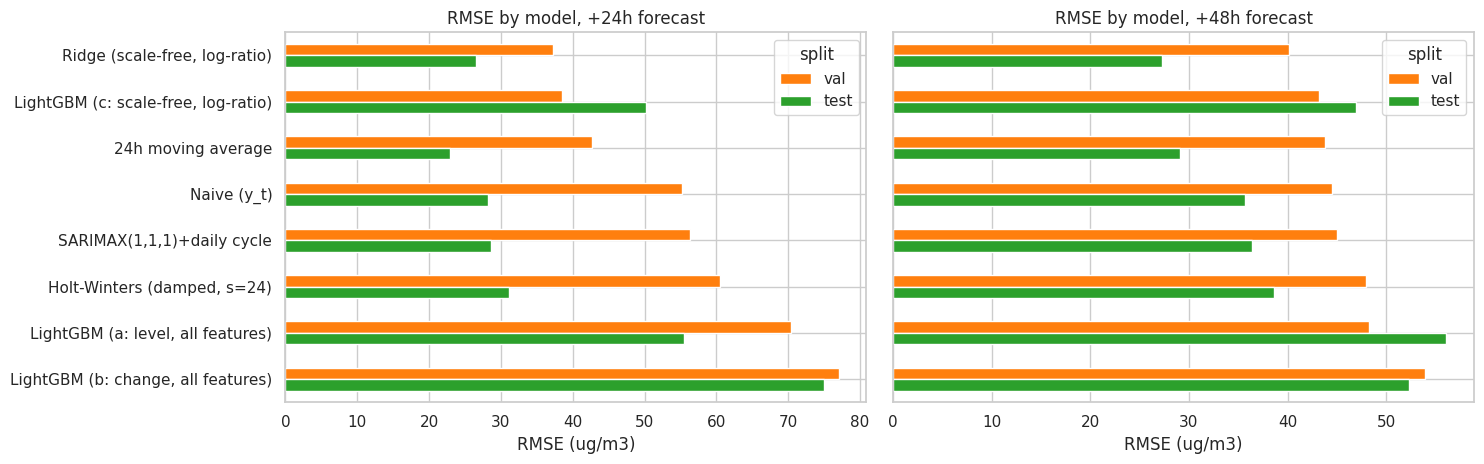

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 4.8), sharey=True)
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    d = res[res.horizon == f"+{h}h"].pivot(index="model", columns="split", values="RMSE")[["val", "test"]]
    d = d.sort_values("val")
    d.plot.barh(ax=ax, color=["tab:orange", "tab:green"]); ax.invert_yaxis()
    ax.set_title(f"RMSE by model, +{h}h forecast"); ax.set_xlabel("RMSE (ug/m3)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### How much can we trust the test numbers?
The test set is only a few days long and consecutive hours are strongly correlated, so a plain RMSE is a noisy point estimate. A **moving-block bootstrap** (12 h blocks) resamples the test errors to give a rough 95% interval. Where intervals overlap, the ranking of models is not reliable.

In [ ]:
def block_ci(err, block=12, n_boot=400, seed=0):
    e2 = np.asarray(err, dtype=float) ** 2
    n = len(e2); nb = int(np.ceil(n / block)); rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=nb)
        out.append(np.sqrt(np.concatenate([e2[s:s + block] for s in starts])[:n].mean()))
    return np.percentile(out, [2.5, 97.5])

rows = []
for h in HORIZONS:
    ix = split_idx(h, "test"); yt = actual(h, ix)
    for name, p in preds[h].items():
        err = (yt - p.loc[ix]).values
        lo, hi = block_ci(err)
        rows.append({"horizon": f"+{h}h", "model": name, "test_RMSE": np.sqrt((err ** 2).mean()), "CI95_low": lo, "CI95_high": hi})
ci = pd.DataFrame(rows).round(1)
display(ci.sort_values(["horizon", "test_RMSE"]).set_index(["horizon", "model"]))

test_RMSE  CI95_low  CI95_high
horizon model                                                              
+24h    Ridge (scale-free, log-ratio)             22.9      18.6       27.7
        24h moving average                        26.5      21.8       30.7
        Naive (y_t)                               28.2      24.5       32.7
        SARIMAX(1,1,1)+daily cycle                28.6      24.9       33.4
        Holt-Winters (damped, s=24)               31.1      26.9       36.2
        LightGBM (c: scale-free, log-ratio)       50.2      41.6       59.9
        LightGBM (b: change, all features)        55.5      44.6       68.4
        LightGBM (a: level, all features)         75.0      68.8       83.1
+48h    Ridge (scale-free, log-ratio)             27.3      18.1       36.3
        24h moving average                        29.1      20.1       38.6
        Naive (y_t)                               35.7      25.8       41.6
        SARIMAX(1,1,1)+daily cycle                36.4      26.6       42.4
        Holt-Winters (damped, s=24)               38.6      28.4       44.6
        LightGBM (c: scale-free, log-ratio)       46.9      37.4       57.5
        LightGBM (b: change, all features)        52.3      38.9       66.6
        LightGBM (a: level, all features)         56.1      43.2       70.2

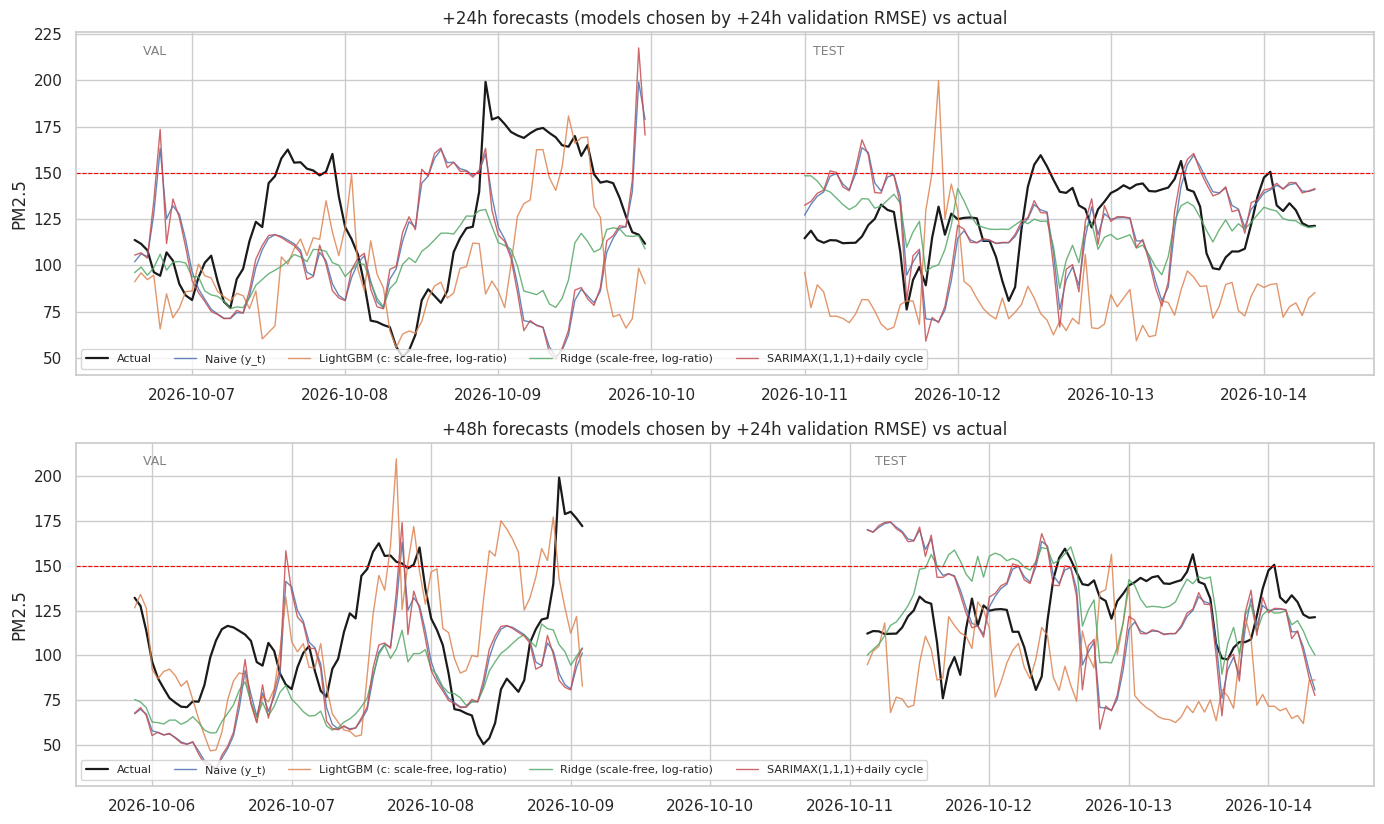

In [ ]:
# Forecast vs actual (x-axis = the time being forecast); val and test windows drawn separately
show_models = ["Naive (y_t)"] + list(res[(res.horizon == f"+{HORIZONS[0]}h") & (res.split == "val") & ~res.model.isin(["Naive (y_t)", "24h moving average"])]
                                      .sort_values("RMSE").model[:3])
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 4.2 * len(HORIZONS)))
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    for k, sp in enumerate(["val", "test"]):
        ix = split_idx(h, sp); tt = ix + h * H
        ax.plot(tt, actual(h, ix).values, color="k", lw=1.6, label="Actual" if k == 0 else None)
        for j, name in enumerate(show_models):
            ax.plot(tt, preds[h][name].loc[ix].values, lw=1, alpha=0.85, color=f"C{j}", label=name if k == 0 else None)
        ax.text(tt[0], ax.get_ylim()[1] * 0.97, "  " + sp.upper(), va="top", fontsize=9, color="grey")
    ax.axhline(HIGH_THR, color="red", ls="--", lw=0.8)
    ax.set_title(f"+{h}h forecasts (models chosen by +{HORIZONS[0]}h validation RMSE) vs actual"); ax.set_ylabel("PM2.5")
    ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### Spike alerts (PM2.5 above 150 ug/m3, NEA "High" band)
A forecast above 150 counts as an alert. No threshold tuning. **Warning:** the number of real high hours is small (shown in `actual_high_hours`), so precision and recall here are only indicative.

In [ ]:
def alerts(h, sp):
    ix = split_idx(h, sp); truth = actual(h, ix) > HIGH_THR; out = []
    for name, p in preds[h].items():
        pr = p.loc[ix] > HIGH_THR
        tp, fp, fn = int((pr & truth).sum()), int((pr & ~truth).sum()), int((~pr & truth).sum())
        out.append({"horizon": f"+{h}h", "split": sp, "model": name, "actual_high_hours": int(truth.sum()),
                    "TP": tp, "FP": fp, "FN": fn,
                    "precision": round(tp / (tp + fp), 2) if tp + fp else np.nan,
                    "recall": round(tp / (tp + fn), 2) if tp + fn else np.nan})
    return out

alert_tbl = pd.DataFrame([r for h in HORIZONS for sp in ["val", "test"] for r in alerts(h, sp)])
display(alert_tbl.set_index(["horizon", "split", "model"]))

actual_high_hours  TP  FP  FN  precision  recall
horizon split model                                                                                
+24h    val   Naive (y_t)                                         25   1  10  24       0.09    0.04
              24h moving average                                  25   0   0  25        NaN    0.00
              SARIMAX(1,1,1)+daily cycle                          25   1  11  24       0.08    0.04
              Holt-Winters (damped, s=24)                         25   1  13  24       0.07    0.04
              LightGBM (a: level, all features)                   25   0   0  25        NaN    0.00
              LightGBM (b: change, all features)                  25   0   0  25        NaN    0.00
              LightGBM (c: scale-free, log-ratio)                 25   7   0  18       1.00    0.28
              Ridge (scale-free, log-ratio)                       25   0   0  25        NaN    0.00
        test  Naive (y_t)                                          5   0   5   5       0.00    0.00
              24h moving average                                   5   0   3   5       0.00    0.00
              SARIMAX(1,1,1)+daily cycle                           5   0   8   5       0.00    0.00
              Holt-Winters (damped, s=24)                          5   1  10   4       0.09    0.20
              LightGBM (a: level, all features)                    5   0   0   5        NaN    0.00
              LightGBM (b: change, all features)                   5   0   0   5        NaN    0.00
              LightGBM (c: scale-free, log-ratio)                  5   0   2   5       0.00    0.00
              Ridge (scale-free, log-ratio)                        5   0   0   5        NaN    0.00
+48h    val   Naive (y_t)                                         13   1   0  12       1.00    0.08
              24h moving average                                  13   0   0  13        NaN    0.00
              SARIMAX(1,1,1)+daily cycle                          13   1   1  12       0.50    0.08
              Holt-Winters (damped, s=24)                         13   1   2  12       0.33    0.08
              LightGBM (a: level, all features)                   13   0   0  13        NaN    0.00
              LightGBM (b: change, all features)                  13   0   0  13        NaN    0.00
              LightGBM (c: scale-free, log-ratio)                 13   3  10  10       0.23    0.23
              Ridge (scale-free, log-ratio)                       13   0   0  13        NaN    0.00
        test  Naive (y_t)                                          5   0  14   5       0.00    0.00
              24h moving average                                   5   0  14   5       0.00    0.00
              SARIMAX(1,1,1)+daily cycle                           5   1  17   4       0.06    0.20
              Holt-Winters (damped, s=24)                          5   1  16   4       0.06    0.20
              LightGBM (a: level, all features)                    5   0   0   5        NaN    0.00
              LightGBM (b: change, all features)                   5   0   0   5        NaN    0.00
              LightGBM (c: scale-free, log-ratio)                  5   0   1   5       0.00    0.00
              Ridge (scale-free, log-ratio)                        5   3  16   2       0.16    0.60

## Part 3 · 6. Shortlist for tuning (Phase 5)
The two strongest **non-baseline** models by mean validation RMSE across the two horizons. The test set plays no part in this choice.

In [ ]:
CANDIDATES = [m for m in preds[HORIZONS[0]] if m not in ("Naive (y_t)", "24h moving average")]
val_rank = (res[(res.split == "val") & res.model.isin(CANDIDATES)]
            .pivot_table(index="model", columns="horizon", values="RMSE"))
val_rank["mean_val_RMSE"] = val_rank.mean(axis=1)
val_rank = val_rank.sort_values("mean_val_RMSE").round(2)
display(val_rank)
TOP2 = list(val_rank.index[:2])
print("Shortlisted for Phase 5 tuning:", TOP2)

horizon,+24h,+48h,mean_val_RMSE
model,,,
"LightGBM (c: scale-free, log-ratio)",38.46,43.18,40.82
"Ridge (scale-free, log-ratio)",42.74,40.11,41.43
"SARIMAX(1,1,1)+daily cycle",56.27,44.96,50.62
"Holt-Winters (damped, s=24)",60.49,47.92,54.21
"LightGBM (b: change, all features)",70.39,53.95,62.17
"LightGBM (a: level, all features)",77.03,48.23,62.63


Shortlisted for Phase 5 tuning: ['LightGBM (c: scale-free, log-ratio)', 'Ridge (scale-free, log-ratio)']


### Reading these results (and their limits)
Numbers below are from this run on the provided data (see the tables above).
1. **No model clearly beats the simple baselines.** At +24h the 24h moving average is the best on validation (RMSE 37.2), with LightGBM (c) close (38.5) and the scale-free Ridge behind (42.7). On the test set the order changes: Ridge is best (22.9 vs 26.5 for the moving average) while LightGBM (c) is much worse (50.2). Rankings flip between validation and test, and the bootstrap intervals overlap heavily, so we cannot claim any candidate is reliably better than the moving average.
2. **Ridge's test result probably reflects the test window, not skill.** Its forecasts are smooth and stay in a 100-130 ug/m3 band (see the plot). The test period happens to sit in a similar plateau, which rewards that behaviour; on the more volatile validation period the same model is worse than the moving average.
3. **Absolute-level ML models fail** (RMSE 50-77 on test): trained on a calmer period, they do not carry over to the higher-level period. Scale-free features and a log-ratio target remove most of that problem, but the design was chosen after seeing validation results.
4. **SARIMAX and Holt-Winters are about equal to naive** (skill between -0.10 and 0.00). With strong persistence and no external driver there is little for them to add beyond "tomorrow looks like today".
5. **Spike alerts are unreliable.** Most models never forecast above 150 ug/m3 and miss nearly all real high hours; the one that does (LightGBM c) catches 7 of 25 on validation at +24h but 0 of 5 on test, with false alarms. Too few events to say more.
6. **Why this is expected:** no upwind information (wind, fire hotspots) is available. A forecast built only from Singapore's own readings can describe persistence and the daily cycle but cannot anticipate haze that has not yet arrived.

---
# Limitations and caveats (running log)
These apply to every result in this notebook and should be repeated in the report and presentation.

**Data**
1. **Short history.** Only 2 stations over 25.6 days (18 Sep - 14 Oct 2026, 615 hours), inside a single haze episode. No annual cycle, no other haze events, no clean-air baseline, so results may not generalise to other years or seasons.
2. **Stations excluded.** Marine Terrace (9 Apr - 7 Jun 2026; its export holds exactly 5,000 rows, which looks like a download limit, so Jun-Oct is missing) and Waterscape at Cavenagh (91 hours only) do not overlap with the other two and were dropped. Spatial conclusions rest on just two sites, so claims about "microclimate sheltering" can only be tentative.
3. **Low-cost sensors.** The data come from AirGradient optical sensors on OpenAQ, not NEA reference monitors. They can over-read in humid or smoky air and were not calibrated here, so absolute PM2.5 values are indicative, not official. NEA's 1-hour bands are used only as a reference scale (the health advisories use the 24-hour PSI, which is not computed).
4. **No wind, no fire hotspot, no upwind data.** The question is about transboundary haze from Indonesian fires, but the dataset only observes Singapore. The models predict from local persistence, the daily cycle, particle composition and local weather; they cannot see haze coming. Statements about wind or fire drivers cannot be supported by these data.
5. **Preprocessing choices.** Hourly averaging; gaps filled by forward-fill for at most 6 hours; exact-zero PM readings treated as sensor dropouts and removed. These are reasonable but not validated against a reference.
6. **City-wide mean of two sensors** is not an area-representative average.

**Modelling and evaluation**
7. **Regime shift.** The training period averages about 62 ug/m3 while validation and test average about 124, with only a handful of training hours above 150. Models must extrapolate to levels barely seen in training.
8. **Very small test set.** About 3.4 days (78-81 hours) with only 5 hours above 150 ug/m3. Metrics are noisy, confidence intervals are wide, and spike-alert precision/recall are only indicative.
9. **Strong autocorrelation.** Hourly rows are not independent (lag-1 autocorrelation about 0.97), so the effective sample size is far smaller than the row count and cross-validation scores will be optimistic and unstable.
10. **Leakage control costs data.** Purging rows near split boundaries (24 or 48 rows each) shrinks the training set (for example 267 training rows at +48h).
11. **Features excluded for lack of evidence.** Month and season indicators (less than one month of data) and day of week (each weekday appears on only 2-3 dates, so any pattern is the haze trend in disguise).
12. **Operational assumption.** Evaluation assumes live, gap-free sensor data at each forecast origin.
13. **No causal claims.** Feature importance and SHAP (Phase 6) will describe what the model uses, not what causes haze.
14. **Validation-guided design.** The scale-free LightGBM / Ridge variants were designed after the absolute-level models failed on validation, so their validation scores are slightly optimistic. The test set was not used for any choice.
15. **Unstable rankings.** Model ranking flips between validation and test, and test intervals overlap; with this little data the best model cannot be identified reliably. Phase 4 models are untuned defaults.
16. **Block-bootstrap intervals are rough.** With a test window of about 80 hours there are only a handful of independent 12-hour blocks.

**Next: Part 4 = Phase 5 hyperparameter tuning** of the two shortlisted models with expanding-window time-series cross-validation, followed by Phase 6 interpretation (importance / SHAP) and the stakeholder recommendations.